# Dataset Statistics: Identification Counts & Coefficients of Variation

Characterises three fundamental quality dimensions of the SCI proteomics dataset across all participating laboratories:

1. **Identification counts** — how many precursors and proteins are detected per single cell, broken down by lab and biological condition.
2. **Coefficients of variation (CVs)** — within-condition reproducibility of quantification, measured as `CV = (std / mean) × 100` per feature.
3. **Missingness heatmap** — binary identification landscape across the full feature space, revealing the sparsity structure and condition-specific detection patterns per lab.

These metrics establish the analytical quality baseline for the dataset and are used in **Figure 3** of the manuscript.

**Inputs** (`Data/AnnData/`)

| File | Description |
|---|---|
| `adata_precursor.h5ad` | Precursor-level quantification (samples × precursors) |
| `adata_protein.h5ad` | Protein-level quantification (samples × protein groups) |

**Outputs** (`Figures/Figure_3/`)

All figures are saved as png, svg, and pdf.

| Panel | File | Description |
|---|---|---|
| A | `count_boxplots/counts_overview_precursors` | Precursor ID counts, all labs combined |
| A | `count_boxplots/counts_overview_precursors_SPLIT` | Precursor ID counts, one panel per lab |
| A | `count_boxplots/counts_overview_proteins` | Protein ID counts, all labs combined |
| A | `count_boxplots/counts_overview_proteins_SPLIT` | Protein ID counts, one panel per lab |
| A | `count_boxplots/pct_contaminants_<feature>`| Percentage of total identifications coming from contaminants |
| B | `CV/CV_overview_proteins_common_box` | Protein CVs, common proteome |
| B | `CV/CV_overview_proteins_all_box` | Protein CVs, per-condition proteome |
| B | `CV/CV_overview_precursors_common_box` | Precursor CVs, common proteome |
| B | `CV/CV_overview_precursors_all_box` | Precursor CVs, per-condition proteome |
| C | `ID_Heatmap/{lab}_identification_heatmap` | Per-lab binary missingness heatmap (precursor & protein) |
| C | `ID_Heatmap/legend_heatmap_conditions` | Condition colour legend |
| C | `ID_Heatmap/legend_heatmap_identification` | Identification/missing colour legend |

---

## Imports

In [13]:
import os
from tqdm import tqdm
import numpy as np
import pandas as pd
from pathlib import Path
import anndata

from SCI_py.plot.identifications import plot_counts_overview
from SCI_py.metrics.cvs import compute_cv_matrix
from SCI_py.plot.cvs import plot_cvs_overview
from SCI_py.plot.identifications import plot_identification_heatmap

tqdm.pandas()

## 0. Path Configuration

Output directories are resolved relative to the notebook location and created automatically if absent. Both can be overridden via environment variables, which is useful for running the notebook on a different machine, with user-defined storage locations, without editing the notebook.

| Variable | Default | Environment override |
|---|---|---|
| `ROOT_OUT` | `../../Data` | `SCI_DATA_DIR` |
| `FIGURES_OUT` | `../../Figures` | `SCI_FIGURES_DIR` |

AnnData objects are expected under `ROOT_OUT/AnnData/`, produced by `02_Results_to_AnnData.ipynb`.

In [14]:
NOTEBOOK_DIR = Path().resolve()
ROOT_OUT      = NOTEBOOK_DIR / "../../Data"
ROOT_OUT      = ROOT_OUT.resolve()
ROOT_OUT.mkdir(parents=True, exist_ok=True)

# Allow user override via environment variable
ROOT_OUT = Path(os.environ.get("SCI_DATA_DIR", ROOT_OUT))

ROOT_OUT.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {ROOT_OUT}")


#########################
### CHANGE PATHS HERE ###
#########################
# 1. Figure storage
### DIANN
# FIGURES_OUT = NOTEBOOK_DIR / "../../Figures/0_DIANN/v2.6"

### Spectronaut
FIGURES_OUT = NOTEBOOK_DIR / "../../Figures/1_Spectronaut"

# 2. Loading AnnData
ROOT_IN = "/public/conode53/sam/SCI_paper/Zenodo/Data"
# Change if paths don't match.
# Or change the path after AnnData to specify search result of given search tool.
### DIANN
# ADATA_PRECURSOR_PATH = os.path.join(ROOT_OUT, 'AnnData', 'DIANN', 'v2.6', 'second_pass', 'base', 'adata_precursor.h5ad')
# ADATA_PROTEIN_PATH =  os.path.join(ROOT_OUT, 'AnnData', 'DIANN', 'v2.6', 'second_pass', 'base', 'adata_protein.h5ad')

### Spectronaut
ADATA_PRECURSOR_PATH = os.path.join(
    ROOT_IN,
    'AnnData',
    'Spectronaut',
    # 'base',
    'adata_precursor.h5ad'
)
ADATA_PROTEIN_PATH =  os.path.join(
    ROOT_IN,
    'AnnData',
    'Spectronaut',
    # 'base',
    'adata_protein.h5ad'
)

FIGURES_OUT = FIGURES_OUT.resolve()
FIGURES_OUT.mkdir(parents=True, exist_ok=True)

# Overwrite with environment variable
FIGURES_OUT = Path(os.environ.get("SCI_FIGURES_DIR", FIGURES_OUT))
print(f"Figures directory: {FIGURES_OUT}")

if not os.path.exists(ADATA_PRECURSOR_PATH):
    print(f'Warning: File not found at {ADATA_PRECURSOR_PATH}. Specify the correct path to the AnnData object.')
if not os.path.exists(ADATA_PROTEIN_PATH):
    print(f'Warning: File not found at {ADATA_PROTEIN_PATH}. Specify the correct path to the AnnData object.')

Output directory: /home/sam/SCI/SCI/Data
Figures directory: /home/sam/SCI/SCI/Figures/1_Spectronaut


In [3]:
SHOW_FIGURES = True

## 1. Load Data

Load the pre-processed AnnData objects for **precursor-level** and **protein-level** quantification. For Spectronaut results, both contain 3,114 samples (observations) with shared `obs` metadata (morphological measurements, experimental annotations, QC flags) but different feature spaces — 72,061 precursors and 7231 protein groups at the time of writing. Raw intensities are in `adata.X`; log₂-transformed intensities are in `adata.layers['X_log2']`.

In [15]:
adata_precursor = anndata.io.read_h5ad(ADATA_PRECURSOR_PATH)
adata_protein = anndata.io.read_h5ad(ADATA_PROTEIN_PATH)

In [5]:
adata_precursor

AnnData object with n_obs × n_vars = 3114 × 72061
    obs: 'sample_name', 'plate_id', 'plate_idx', 'source name', 'comment[X position]', 'comment[Y position]', 'comment[Plate Number]', 'comment[Gradient time]', 'comment[thawing timepoint]', 'comment[plate arrival]', 'injection_order', 'institute_name', 'Reinjection', 'Diameter', 'Elongation', 'Circularity', 'Doublet', 'Dividing', 'Dying', 'CellInBlank', 'comment[plate arrival]_date', 'comment[plate arrival]_time', 'comment[plate arrival]_datetime', 'comment[Gradient time]_date', 'comment[Gradient time]_time', 'comment[Gradient time]_datetime', 'instrument_type', 'n_precursors_withCont', 'n_precursors', 'pct_contaminant', 'completeness_sample_SC', 'completeness_sample_QC', 'completeness_outlier'
    var: 'PG.ProteinGroups', 'PG.ProteinAccessions', 'PEP.StrippedSequence', 'PEP.IsProteotypic', 'EG.ModifiedSequence', 'FG.Charge', 'FG.LabeledSequence', 'PG.Pvalue', 'PG.Qvalue', 'FG.Qvalue', 'EG.GlobalPrecursorQvalue', 'PG.Cscore', 'EG.ApexR

In [6]:
adata_protein

AnnData object with n_obs × n_vars = 3114 × 7231
    obs: 'sample_name', 'plate_id', 'plate_idx', 'source name', 'comment[X position]', 'comment[Y position]', 'comment[Plate Number]', 'comment[Gradient time]', 'comment[thawing timepoint]', 'comment[plate arrival]', 'injection_order', 'institute_name', 'Reinjection', 'Diameter', 'Elongation', 'Circularity', 'Doublet', 'Dividing', 'Dying', 'CellInBlank', 'comment[plate arrival]_date', 'comment[plate arrival]_time', 'comment[plate arrival]_datetime', 'comment[Gradient time]_date', 'comment[Gradient time]_time', 'comment[Gradient time]_datetime', 'instrument_type', 'n_proteins_withCont', 'n_proteins', 'pct_contaminant', 'completeness_sample_SC', 'completeness_sample_QC', 'completeness_outlier'
    var: 'PG.ProteinAccessions', 'PEP.StrippedSequence', 'PEP.IsProteotypic', 'EG.ModifiedSequence', 'FG.Charge', 'FG.LabeledSequence', 'FG.PrecursorIon', 'PG.Pvalue', 'PG.Qvalue', 'FG.Qvalue', 'EG.GlobalPrecursorQvalue', 'PG.Cscore', 'EG.ApexRT', 'E

## 2. Identifications

The number of identified precursors/proteins per sample is computed as the count of non-missing (`non-NaN`) entries in `adata.X` and stored in `adata.obs` as `n_precursors` and `n_proteins` respectively. This reflects the number of features quantified in a given single cell after Spectronaut's search.

Box plots are generated for each quantification level in two layouts:

- **Combined** (`split_conditions=False`) — all labs in a single panel, coloured by condition. Gives an overall picture of identification depth across the dataset.
- **Split** (`split_conditions=True`, `show_xlabels=False`) — one panel per lab. Reveals inter-site variability and instrument-platform differences (Astral vs. timsTOF) that are less clear in the combined view.

All figures are saved to `Figures/Figure_3/` without displaying inline (`show=False`) to keep the notebook output lightweight. If you want to see the figures inline, set the SHOW_FIGURES variable (defined above in the notebook) to True.

In [16]:
adata_precursor.obs['n_precursors_withCont'] = np.sum(~np.isnan(adata_precursor.X), axis=1)
adata_protein.obs['n_proteins_withCont'] = np.sum(~np.isnan(adata_protein.X), axis=1)

adata_precursor.obs['n_precursors'] = np.sum(~np.isnan(
    adata_precursor[:, ~adata_precursor.var['Contaminant']].X
), axis=1)
adata_protein.obs['n_proteins'] = np.sum(~np.isnan(
    adata_protein[:, ~adata_protein.var['Contaminant']].X
), axis=1)

# Compute contaminant percentage per cell
adata_protein.obs['pct_contaminant'] = (
    (adata_protein.obs['n_proteins_withCont'] - adata_protein.obs['n_proteins'])
    / adata_protein.obs['n_proteins_withCont'] * 100
)

adata_precursor.obs['pct_contaminant'] = (
    (adata_precursor.obs['n_precursors_withCont'] - adata_precursor.obs['n_precursors'])
    / adata_precursor.obs['n_precursors_withCont'] * 100
)

In [17]:
# ── Mean identifications per lab (K562 & HEK293T single cells, contaminants excluded) ──
_cells_prec = adata_precursor.obs['source name'].isin(['K562', 'HEK293T'])
_cells_prot = adata_protein.obs['source name'].isin(['K562', 'HEK293T'])

counts_table = pd.DataFrame({
    'Mean precursors': adata_precursor.obs[_cells_prec]
                       .groupby('plate_idx', observed=True)['n_precursors'].mean(),
    'Mean proteins':   adata_protein.obs[_cells_prot]
                       .groupby('plate_idx', observed=True)['n_proteins'].mean(),
})
counts_table.index.name = 'lab'
counts_table.round().astype(int)

,Mean precursors,Mean proteins
lab,,
Astral_1,7987,2147
Astral_2,10946,2847
Astral_3,4571,1597
Astral_4,4938,1268
Astral_5,5472,1621
Astral_6,7487,2108
timsTOF_1,8726,1766
timsTOF_2,10270,2058
timsTOF_3,7641,1741


In [18]:
# Mean relative protein-ID gain of the best Astral lab (Astral_2) over the timsTOF labs
_prot = counts_table['Mean proteins']
_tims = ['timsTOF_1', 'timsTOF_2', 'timsTOF_3']
((_prot['Astral_2'] - _prot[_tims]) / _prot[_tims]).mean()

np.float64(0.5436469016851244)

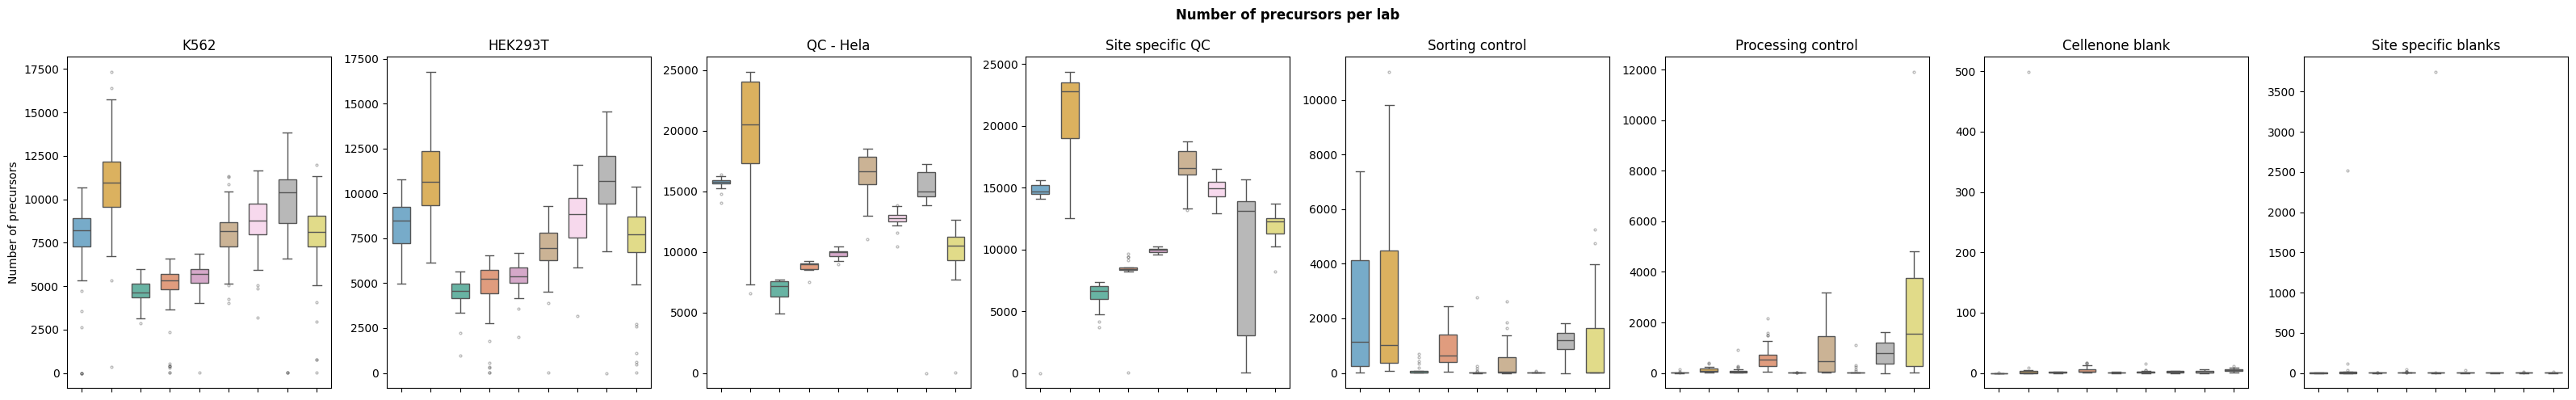

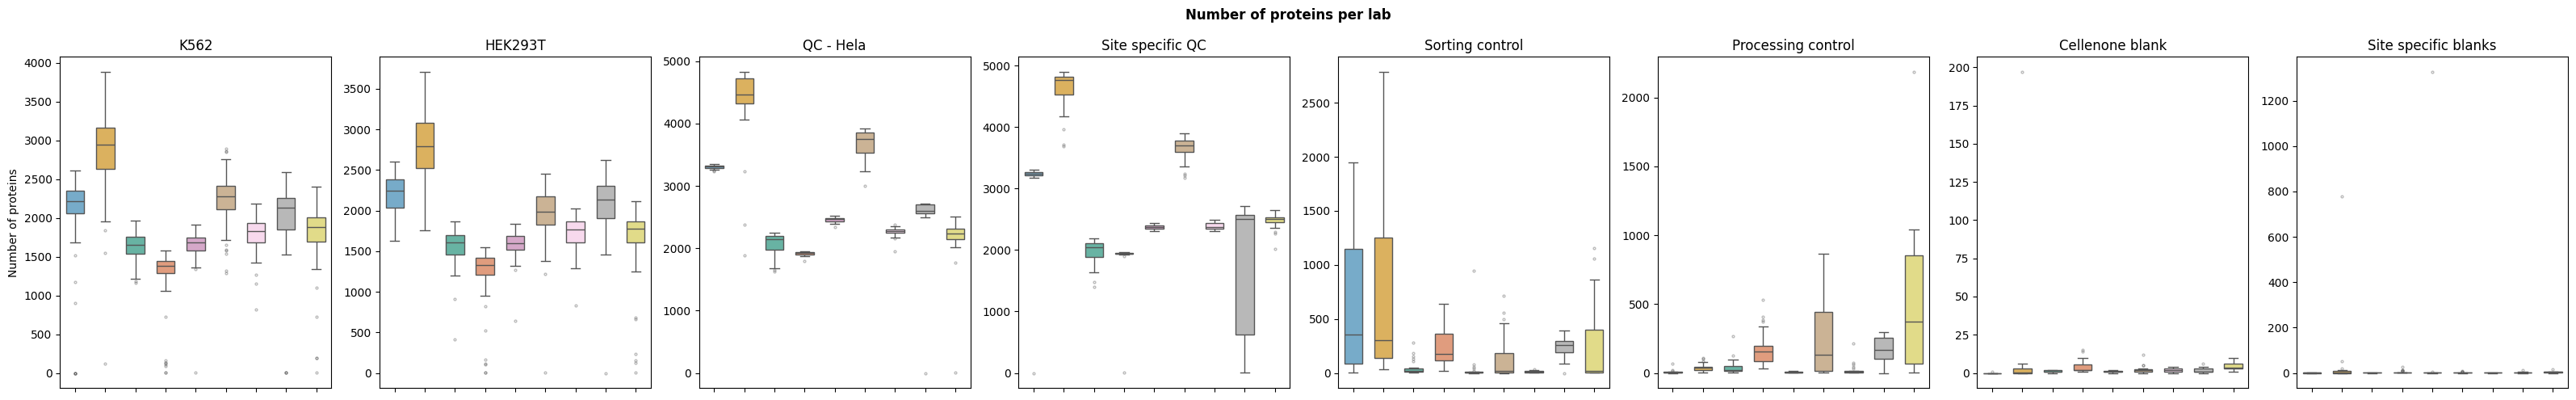

In [10]:
# Precursor boxplots for identifications, splitted view, and shown in one figure
plot_counts_overview(
    adata=adata_precursor,
    count_col='n_precursors',
    split_conditions=True,
    show_xlabels=False,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='counts_overview_precursors_SPLIT.png',
    show=SHOW_FIGURES
)
plot_counts_overview(
    adata=adata_precursor,
    count_col='n_precursors',
    split_conditions=False,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='counts_overview_precursors.png',
    show=False
)

# Protein boxplots for identifications, splitted view, and shown in one figure
plot_counts_overview(
    adata=adata_protein,
    count_col='n_proteins',
    split_conditions=True,
    show_xlabels=False,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='counts_overview_proteins_SPLIT.png',
    show=SHOW_FIGURES
)
plot_counts_overview(
    adata=adata_protein,
    count_col='n_proteins',
    split_conditions=False,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='counts_overview_proteins.png',
    show=False
)

The percentage of contaminant identifications in the samples indicates the relative abundance of non-specific background signal compared to true cellular proteome signal. It is expected that blanks and processing control samples contain the most contaminant proteins, since no cellular material is present in these samples. If some of these blank samples do contain many non-contaminant proteins, this could indicate a sample contaminated with carry-over material from the LC or bad integrity of the sealed-plate shipment. Conversely, single-cell and HeLa QC samples are expected to show low contaminant fractions, reflecting a proteome signal dominated by cellular content. Sorting controls, which contain sorting liquid but no cell, are expected to behave similarly to blanks. An unexpectedly high contaminant fraction in cell-containing samples may point to issues during cell isolation, insufficient lysis, or degradation of cellular material during shipment or storage.

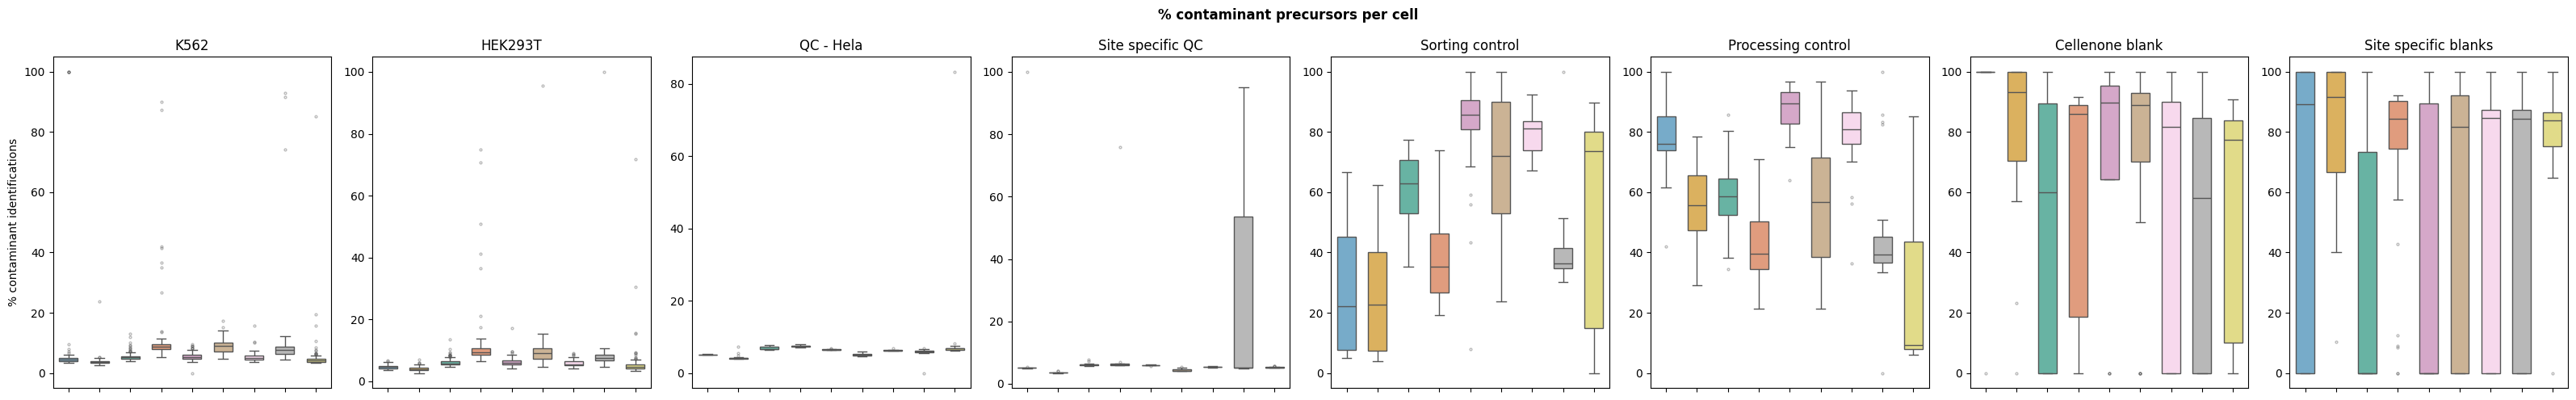

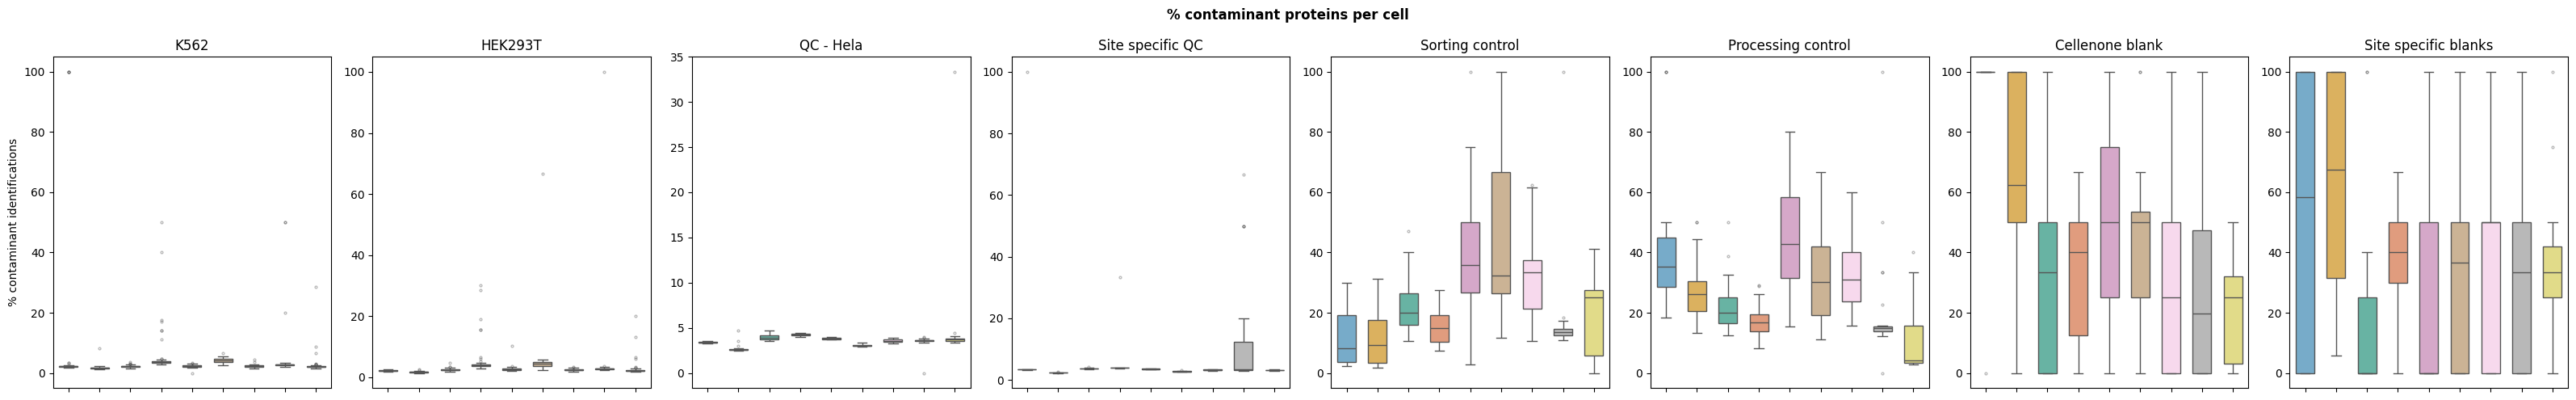

In [11]:
plot_counts_overview(
    adata_precursor,
    count_col        = 'pct_contaminant',
    split_conditions = True,
    title            = '% contaminant precursors per cell',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='pct_contaminants_precursors.png',
    show=True
)
plot_counts_overview(
    adata_protein,
    count_col        = 'pct_contaminant',
    split_conditions = True,
    title            = '% contaminant proteins per cell',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'count_boxplots'),
    filename='pct_contaminants_proteins.png',
    show=True
)

## 3. Coefficients of Variation (CVs)

CVs quantify measurement reproducibility: a CV of 20% means the standard deviation of a feature's intensity across samples is 20% of its mean. Lower CVs indicate better reproducibility. CVs are computed independently for four biological conditions — **K562**, **HEK293T**, **QC - HeLa**, and **Site-specific QC** — and stored in `adata.uns['CVs']` for both protein and precursor levels.

**Key parameters**
- `min_n = 10` — a feature must be quantified in at least 10 samples within a condition to contribute to the CV distribution. This threshold prevents unreliable CV estimates from features detected in only a handful of cells.
- `ylim = 130` — y-axis cap at 130% CV, excluding extreme outliers from the visual summary while retaining all data in `adata.uns['CVs']`.

**Two proteome subsets** are compared side-by-side:
- **Common proteome** (`common_proteome=True`) — only features passing `min_n` in *all* conditions simultaneously. This enables a fair cross-condition CV comparison on the same set of features.
- **All features** (`common_proteome=False`) — features passing `min_n` within each condition independently, maximising the number of features per condition but making direct cross-condition comparisons less straightforward.

Both subsets are plotted at protein and precursor level, producing four figures in total per level.

In [19]:
protein_cvs = compute_cv_matrix(
    adata=adata_protein[:, ~adata_protein.var['Contaminant']],
    conditions=[
        'K562',
        'HEK293T',
        'QC - Hela',
        'Site specific QC'
    ]
)
precursor_cvs = compute_cv_matrix(
    adata=adata_precursor[:, ~adata_precursor.var['Contaminant']],
    conditions=[
        'K562',
        'HEK293T',
        'QC - Hela',
        'Site specific QC'
    ]
)

adata_protein.uns['CVs'] = protein_cvs
adata_precursor.uns['CVs'] = precursor_cvs

In [20]:
# ── Combined per-lab overview: mean & median identification counts + median CVs ──
# Single table indexed by lab. Counts are the mean and median IDs over K562 &
# HEK293T single cells (contaminants excluded, from section 2); CVs are the
# median CV (%) per condition, at precursor and protein level.
_cv_conditions = ['K562', 'HEK293T', 'QC - Hela', 'Site specific QC']
_sc_conditions = ['K562', 'HEK293T']

def _median_cv_table(cvs):
    return (
        cvs[cvs['condition'].isin(_cv_conditions)]
        .groupby(['lab', 'condition'], observed=True)['cv']
        .median()
        .unstack('condition')[_cv_conditions]
    )

def _count_summary(adata, count_col, label):
    g = (
        adata.obs[adata.obs['source name'].isin(_sc_conditions)]
        .groupby('plate_idx', observed=True)[count_col]
    )
    return pd.DataFrame({
        f'{label} (mean)':   g.mean(),
        f'{label} (median)': g.median(),
    })

count_summary = pd.concat(
    [
        _count_summary(adata_precursor, 'n_precursors', 'precursors'),
        _count_summary(adata_protein,   'n_proteins',   'proteins'),
    ],
    axis=1,
)

summary_table = pd.concat(
    {
        'Counts':                  count_summary,
        'Median CV % (precursor)': _median_cv_table(adata_precursor.uns['CVs']),
        'Median CV % (protein)':   _median_cv_table(adata_protein.uns['CVs']),
    },
    axis=1,
)
summary_table.index.name = 'lab'
summary_table.round(1)

Counts                                      \
          precursors (mean) precursors (median) proteins (mean)   
lab                                                               
Astral_1             7986.9              8350.0          2147.0   
Astral_2            10945.7             10708.5          2847.5   
Astral_3             4571.4              4602.0          1597.1   
Astral_4             4938.5              5290.5          1268.5   
Astral_5             5471.6              5551.0          1620.9   
Astral_6             7487.1              7624.5          2108.5   
timsTOF_1            8726.2              8824.0          1766.0   
timsTOF_2           10269.7             10464.5          2058.5   
timsTOF_3            7641.5              7942.0          1741.3   

                            Median CV % (precursor)                    \
          proteins (median)                    K562 HEK293T QC - Hela   
lab                                                                     
Astral_1             2233.5                    55.1    56.3      44.7   
Astral_2             2849.5                    51.8    53.5      38.8   
Astral_3             1622.0                    50.5    48.6      53.3   
Astral_4             1360.5                    44.3    40.9      28.9   
Astral_5             1645.5                    43.8    43.8      40.5   
Astral_6             2143.5                    43.4    43.6      40.3   
timsTOF_1            1789.0                    51.2    48.7      38.0   
timsTOF_2            2132.5                    52.3    49.6      33.6   
timsTOF_3            1832.0                    45.7    45.7      48.0   

                           Median CV % (protein)                    \
          Site specific QC                  K562 HEK293T QC - Hela   
lab                                                                  
Astral_1              52.8                  54.3    55.2      39.2   
Astral_2              34.5                  53.7    54.5      35.0   
Astral_3              54.0                  49.7    47.3      51.2   
Astral_4              24.9                  46.2    42.3      23.4   
Astral_5              36.0                  42.9    43.1      34.8   
Astral_6              42.1                  46.8    46.3      35.5   
timsTOF_1             36.6                  52.7    49.2      34.1   
timsTOF_2             32.0                  55.3    51.7      29.9   
timsTOF_3             46.4                  46.2    45.8      44.2   

                            
          Site specific QC  
lab                         
Astral_1              47.1  
Astral_2              30.7  
Astral_3              50.5  
Astral_4              20.4  
Astral_5              30.2  
Astral_6              38.0  
timsTOF_1             31.5  
timsTOF_2             28.8  
timsTOF_3             42.6

In [31]:
tims = ['timsTOF_1', 'timsTOF_2', 'timsTOF_3']
astral_refs = ['Astral_1' ,'Astral_3', 'Astral_4', 'Astral_5', 'Astral_6']

astral2_proteins = counts_table.loc['Astral_2', 'Mean proteins']

avg_pct_vs_all = (
    (astral2_proteins - counts_table.loc[tims, 'Mean proteins'])
    / counts_table.loc[tims, 'Mean proteins']
).mean() * 100

avg_pct_vs_all


np.float64(54.36469016851244)

In [23]:
# ── Mean & median CVs per lab, replicating the plot filtering ──
# Reproduces the exact filtering applied inside plot_cvs_overview, so these
# numbers match the CV boxplots below:
#   1. keep rows whose condition is in CONDITION_ORDER and n >= min_n (min_n=10)
#   2. common proteome: additionally restrict to features quantified in ALL
#      labs, per condition (via _filter_common_proteome)
# The table is produced for both proteome subsets (per-condition vs common)
# and both feature levels (precursor, protein).
from SCI_py.plot.cvs import _filter_common_proteome
from SCI_py.constants.plotting import CONDITION_ORDER

_MIN_N = 10
_cv_conditions = ['K562', 'HEK293T', 'QC - Hela', 'Site specific QC']

def _filter_like_plot(cvs, min_n=_MIN_N, common_proteome=False):
    """Apply the same filtering as plot_cvs_overview."""
    condition_order = [c for c in CONDITION_ORDER if c in cvs['condition'].unique()]
    out = cvs[cvs['condition'].isin(condition_order) & (cvs['n'] >= min_n)].copy()
    if common_proteome:
        out = _filter_common_proteome(out, condition_order)
    return out

def _cv_stats_table(cvs, common_proteome):
    """Mean & median CV (%) per lab per condition, after plot filtering."""
    sub = _filter_like_plot(cvs, common_proteome=common_proteome)
    g   = sub.groupby(['lab', 'condition'], observed=True)['cv']
    tbl = pd.concat({'mean': g.mean(), 'median': g.median()}, axis=1)  # cols: mean, median
    tbl = tbl.unstack('condition')                                     # cols: (stat, condition)
    tbl = tbl.reindex(
        columns=pd.MultiIndex.from_product([['mean', 'median'], _cv_conditions])
    )
    tbl = tbl.swaplevel(axis=1)                                        # cols: (condition, stat)
    return tbl.reindex(
        columns=pd.MultiIndex.from_product([_cv_conditions, ['mean', 'median']])
    )

cv_summary = pd.concat(
    {
        ('precursor', 'per-condition'): _cv_stats_table(adata_precursor.uns['CVs'], common_proteome=False),
        ('precursor', 'common'):        _cv_stats_table(adata_precursor.uns['CVs'], common_proteome=True),
        ('protein',   'per-condition'): _cv_stats_table(adata_protein.uns['CVs'],   common_proteome=False),
        ('protein',   'common'):        _cv_stats_table(adata_protein.uns['CVs'],   common_proteome=True),
    },
    axis=1,
)
cv_summary.index.name = 'lab'
cv_summary.columns.names = ['level', 'proteome', 'condition', 'stat']
cv_summary.round(1)

level         precursor                                         \
proteome  per-condition                                          
condition          K562        HEK293T        QC - Hela          
stat               mean median    mean median      mean median   
lab                                                              
Astral_1           59.8   55.8    61.0   57.1      47.5   44.6   
Astral_2           58.5   52.9    60.3   54.3      41.0   38.2   
Astral_3           59.1   50.1    53.1   48.6      54.6   53.7   
Astral_4           59.8   44.3    51.3   41.1      31.6   27.5   
Astral_5           49.4   43.8    51.4   43.8      43.4   40.2   
Astral_6           51.1   43.5    49.0   43.9      42.7   39.6   
timsTOF_1          62.6   51.5    53.7   49.2      38.9   36.9   
timsTOF_2          63.8   52.9    56.7   50.4      35.5   32.6   
timsTOF_3          50.5   46.1    50.3   46.1      50.1   48.3   

level                                            ...          protein         \
proteome                          common         ...    per-condition          
condition Site specific QC          K562         ... Site specific QC          
stat                  mean median   mean median  ...             mean median   
lab                                              ...                           
Astral_1              54.7   52.9   59.7   54.3  ...             48.7   47.1   
Astral_2              36.9   33.7   58.5   51.2  ...             34.2   30.4   
Astral_3              55.7   54.4   56.2   47.8  ...             51.8   50.6   
Astral_4              27.9   23.6   53.4   42.3  ...             23.8   19.9   
Astral_5              37.2   35.7   44.4   39.6  ...             32.1   29.7   
Astral_6              45.4   41.7   50.9   38.6  ...             41.5   37.4   
timsTOF_1             37.4   35.4   58.8   46.8  ...             33.4   30.0   
timsTOF_2             32.6   29.7   57.3   50.1  ...             30.9   27.8   
timsTOF_3             47.9   46.5   51.1   45.7  ...             45.3   42.4   

level                                                                     \
proteome  common                                                           
condition   K562        HEK293T        QC - Hela        Site specific QC   
stat        mean median    mean median      mean median             mean   
lab                                                                        
Astral_1    60.6   51.7    62.5   53.8      37.7   36.3             44.6   
Astral_2    59.7   49.6    58.5   50.1      33.3   30.6             26.0   
Astral_3    62.0   47.4    54.5   45.2      50.9   50.5             51.5   
Astral_4    65.2   43.9    54.4   40.1      24.9   21.3             21.9   
Astral_5    48.1   38.6    51.2   39.1      32.8   31.1             26.8   
Astral_6    56.1   40.7    51.1   41.1      32.0   29.9             34.9   
timsTOF_1   63.8   47.0    52.7   44.6      29.6   26.9             27.9   
timsTOF_2   63.8   51.2    56.3   48.1      25.4   22.3             25.9   
timsTOF_3   51.5   43.4    51.2   43.4      44.2   40.6             40.9   

level             
proteome          
condition         
stat      median  
lab               
Astral_1    43.6  
Astral_2    23.4  
Astral_3    50.3  
Astral_4    18.6  
Astral_5    24.3  
Astral_6    32.9  
timsTOF_1   24.8  
timsTOF_2   22.4  
timsTOF_3   37.9  

[9 rows x 32 columns]

In [24]:
cv_summary.to_excel('cv_table.xlsx')

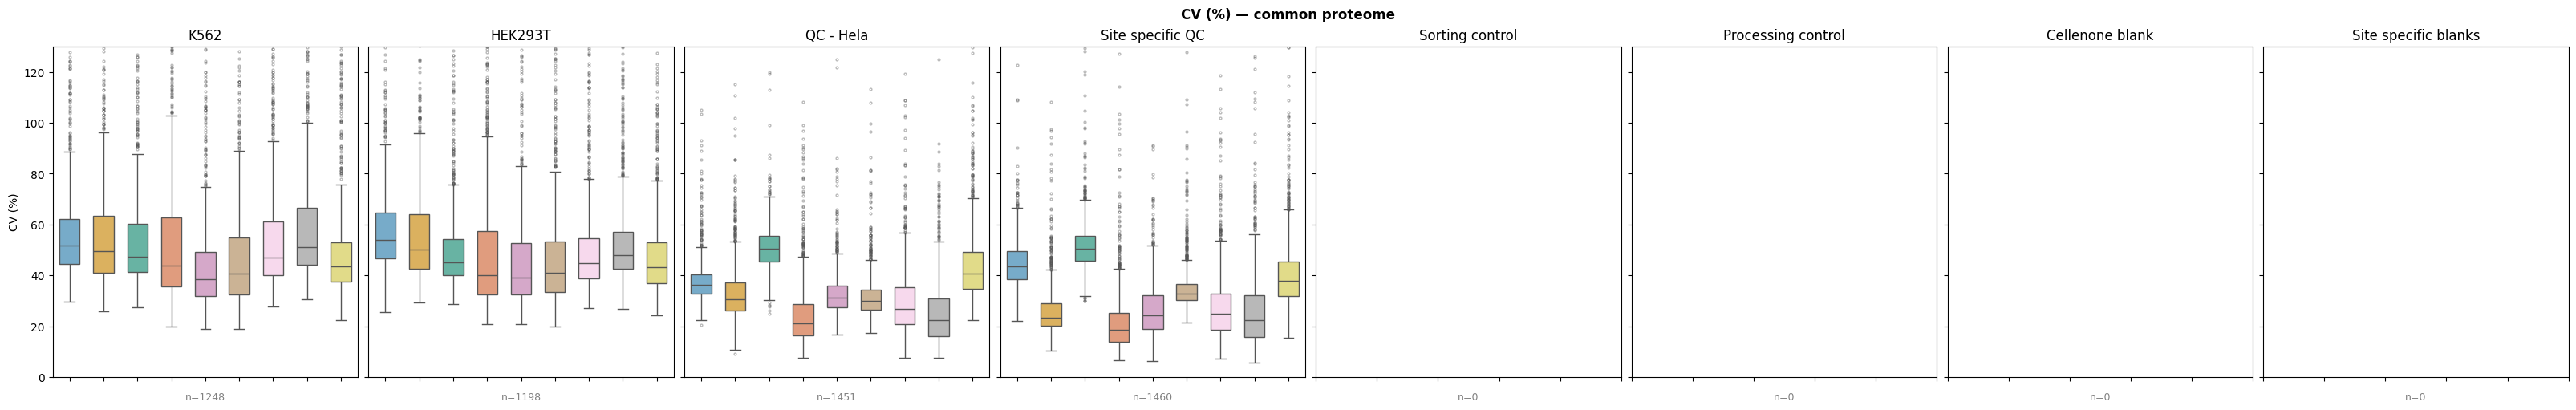

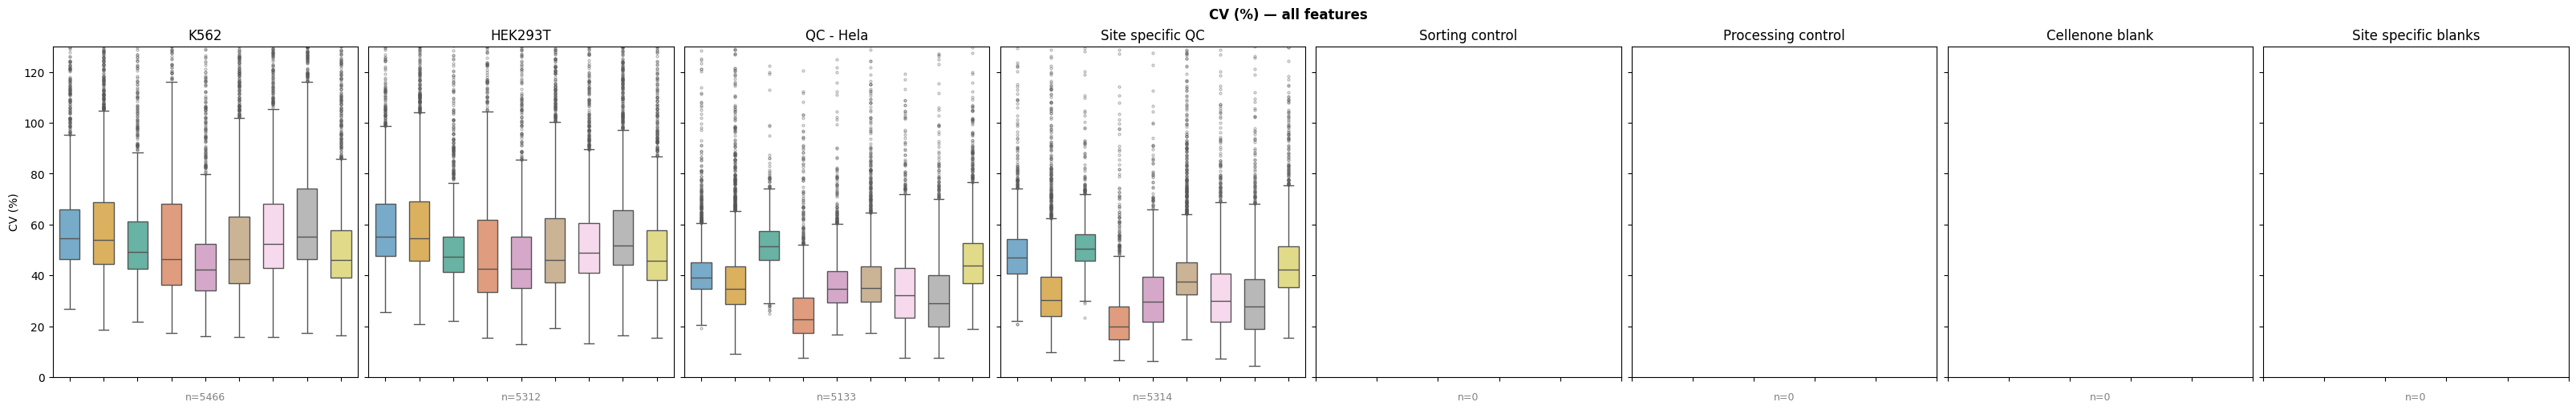

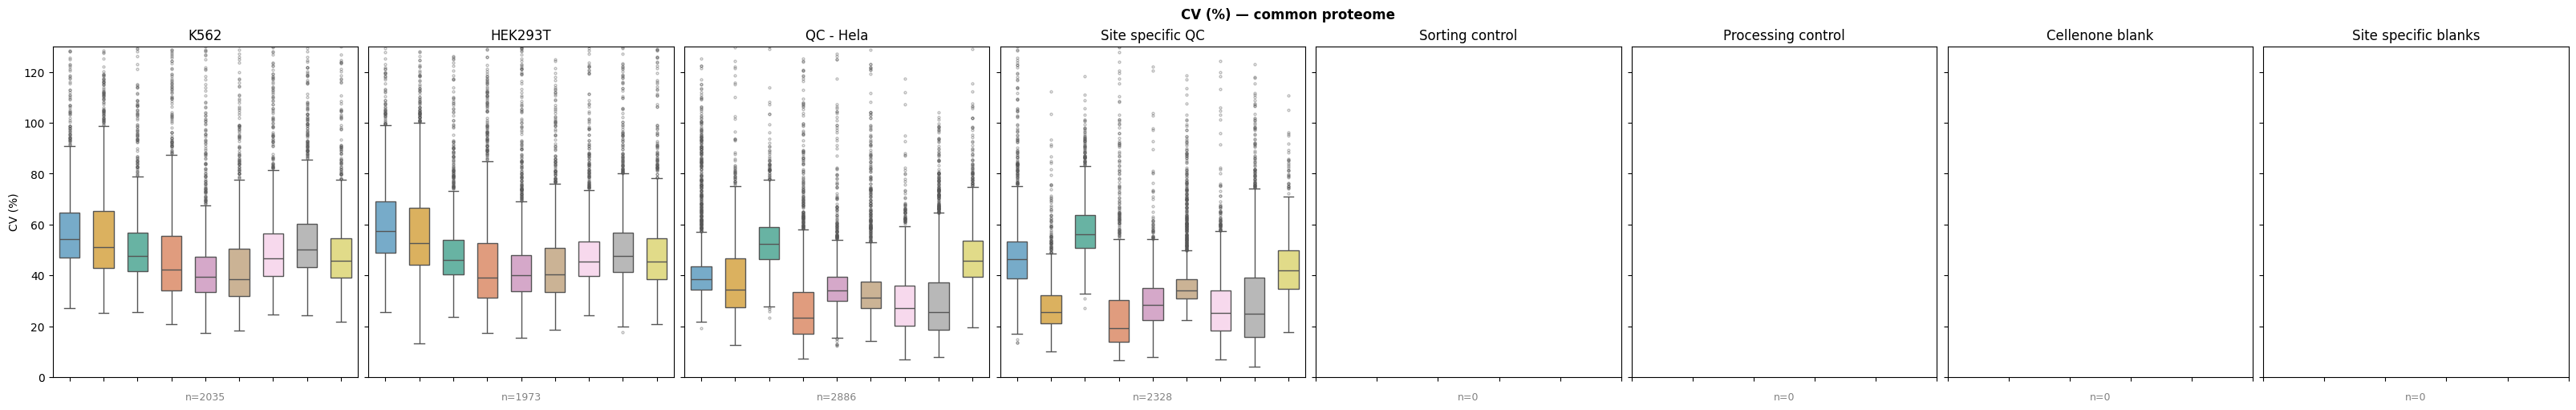

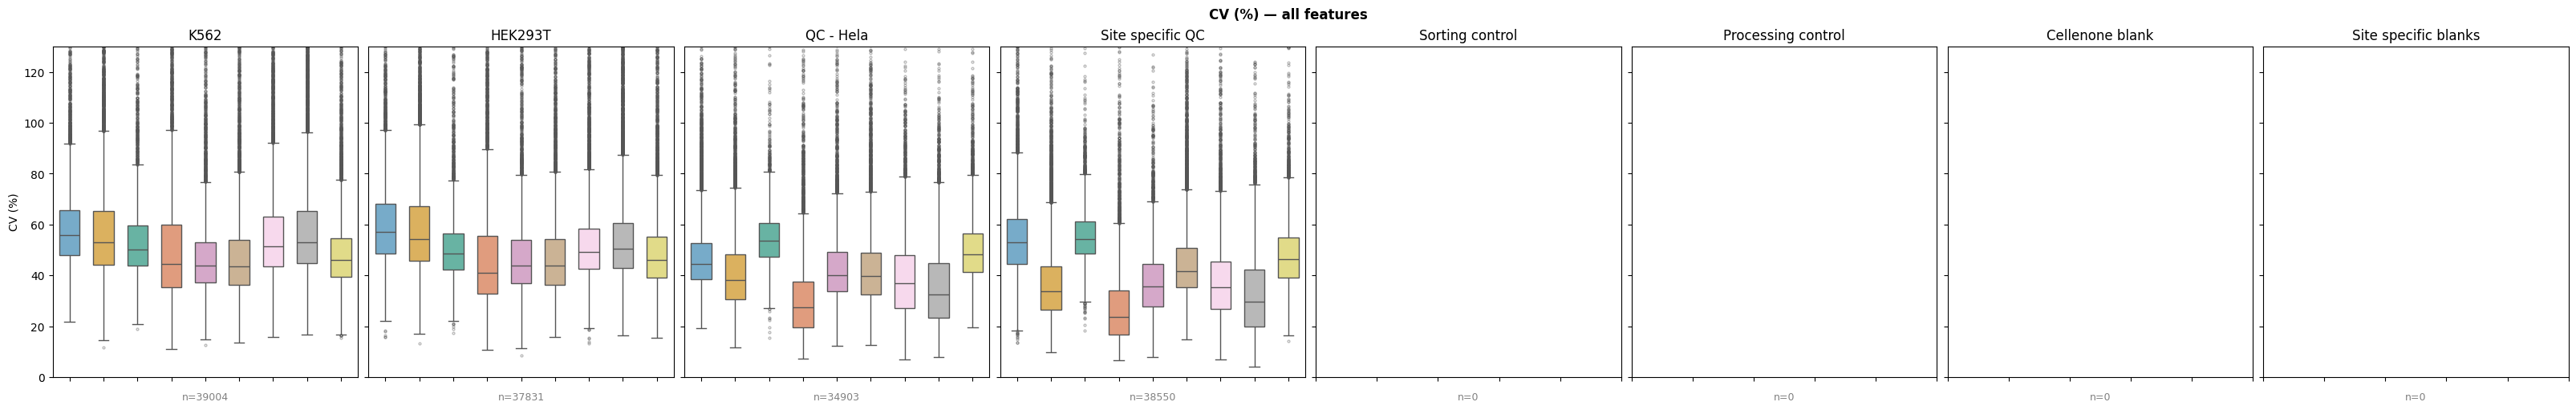

In [22]:
plot_cvs_overview(
    cvs=adata_protein.uns['CVs'],
    split_conditions=True,
    min_n=10,
    common_proteome=True,
    ylim=130,
    plot_type='box',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'CV'),
    filename='CV_overview_proteins_common_box',
    show=SHOW_FIGURES
)
plot_cvs_overview(
    cvs=adata_protein.uns['CVs'],
    split_conditions=True,
    min_n=10,
    common_proteome=False,
    ylim=130,
    plot_type='box',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'CV'),
    filename='CV_overview_proteins_all_box',
    show=SHOW_FIGURES
)

plot_cvs_overview(
    cvs=adata_precursor.uns['CVs'],
    split_conditions=True,
    min_n=10,
    common_proteome=True,
    ylim=130,
    plot_type='box',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'CV'),
    filename='CV_overview_precursors_common_box',
    show=SHOW_FIGURES
)
plot_cvs_overview(
    cvs=adata_precursor.uns['CVs'],
    split_conditions=True,
    min_n=10,
    common_proteome=False,
    ylim=130,
    plot_type='box',
    save_dir=os.path.join(FIGURES_OUT, 'Figure_3', 'CV'),
    filename='CV_overview_precursors_all_box',
    show=SHOW_FIGURES
)

## 4. Missingness Heatmap

Visualises the binary identification landscape (detected / not detected) as a heatmap across all features for each lab separately. Each column is a sample; each row is a precursor or protein group. This plot makes the sparsity structure of single-cell proteomics data immediately apparent and reveals how detection patterns differ between conditions and instruments.

**Layout** — one figure per lab, each with two panels stacked vertically:
- A narrow **condition colour bar** at the top encodes `source name` for each sample.
- The **binary heatmap** below shows detected features in blue and missing values in light grey.

**Sample and feature ordering**
- Samples are grouped by condition (in `CONDITION_ORDER`) and, within each condition, sorted by descending identification count — so the best-covered cells appear first.
- Features are ordered by **global detection frequency** (`global_protein_order=True`), computed across all conditions and labs. The most consistently detected features appear at the top. This global ordering is fixed across all per-lab figures, enabling direct visual comparison of which features are lab-specific versus universally detected.
- The `sort_conditions` parameter restricts the frequency ranking to **K562 and HEK293T** only, so the feature order reflects the two primary biological conditions rather than being influenced by the sparser control and blank samples.

**Subsampling** — K562 and HEK293T cells are capped at `max_samples_per_condition = 50` per lab to keep figure sizes manageable while preserving a representative view of the detection pattern. Control conditions (sorting control, processing control, blank, site-specific blanks) are shown without subsampling.

Heatmaps are generated at both precursor and protein level and saved to `Figures/Figure_3/ID_Heatmap/`.

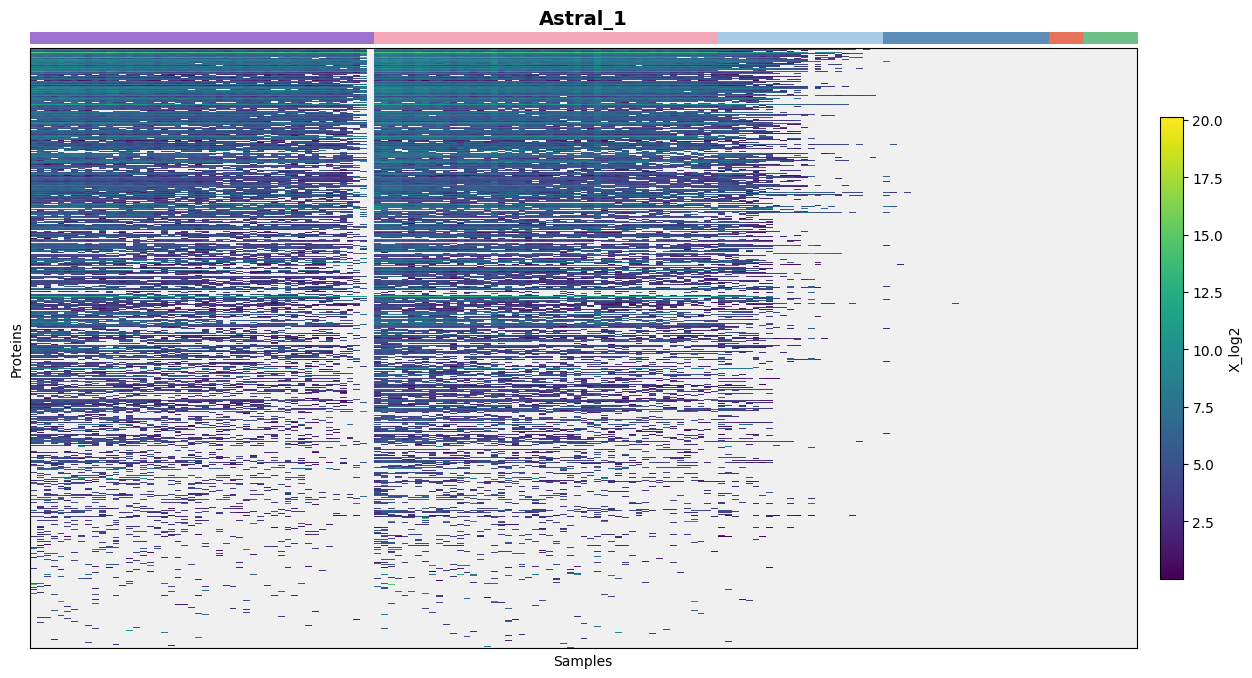

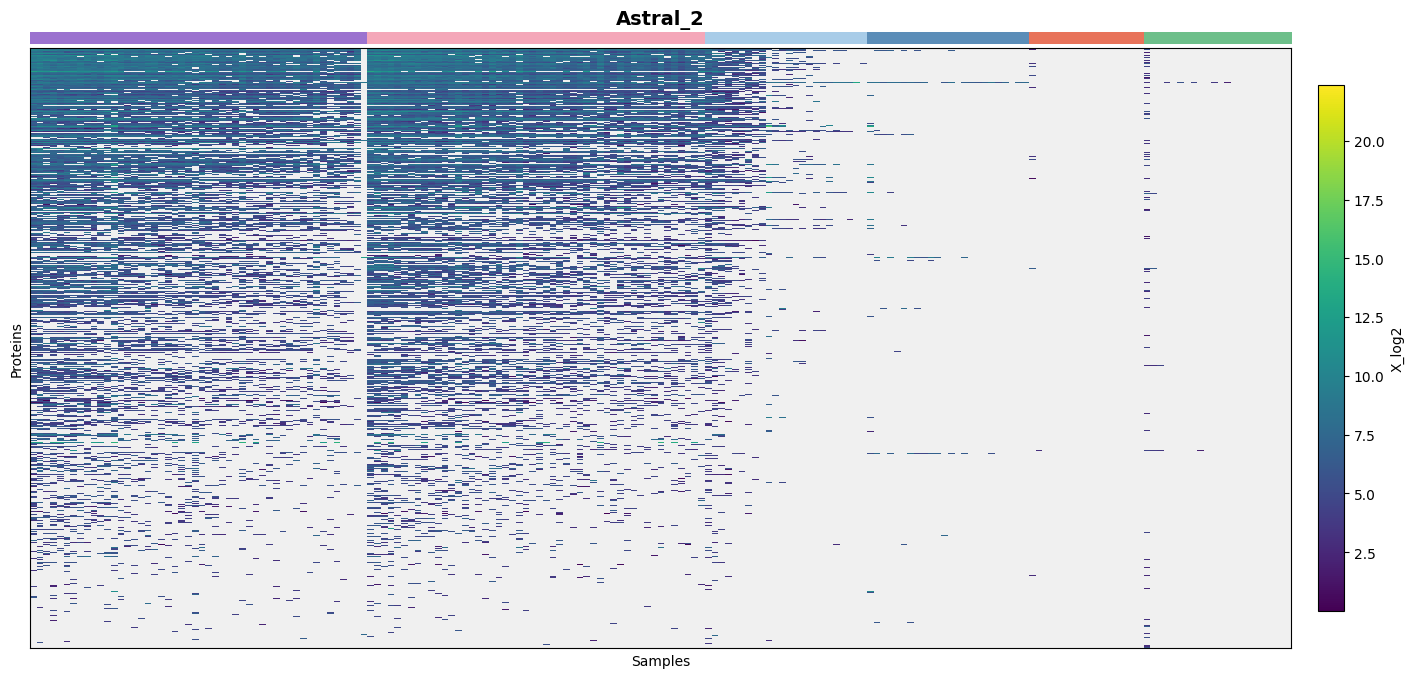

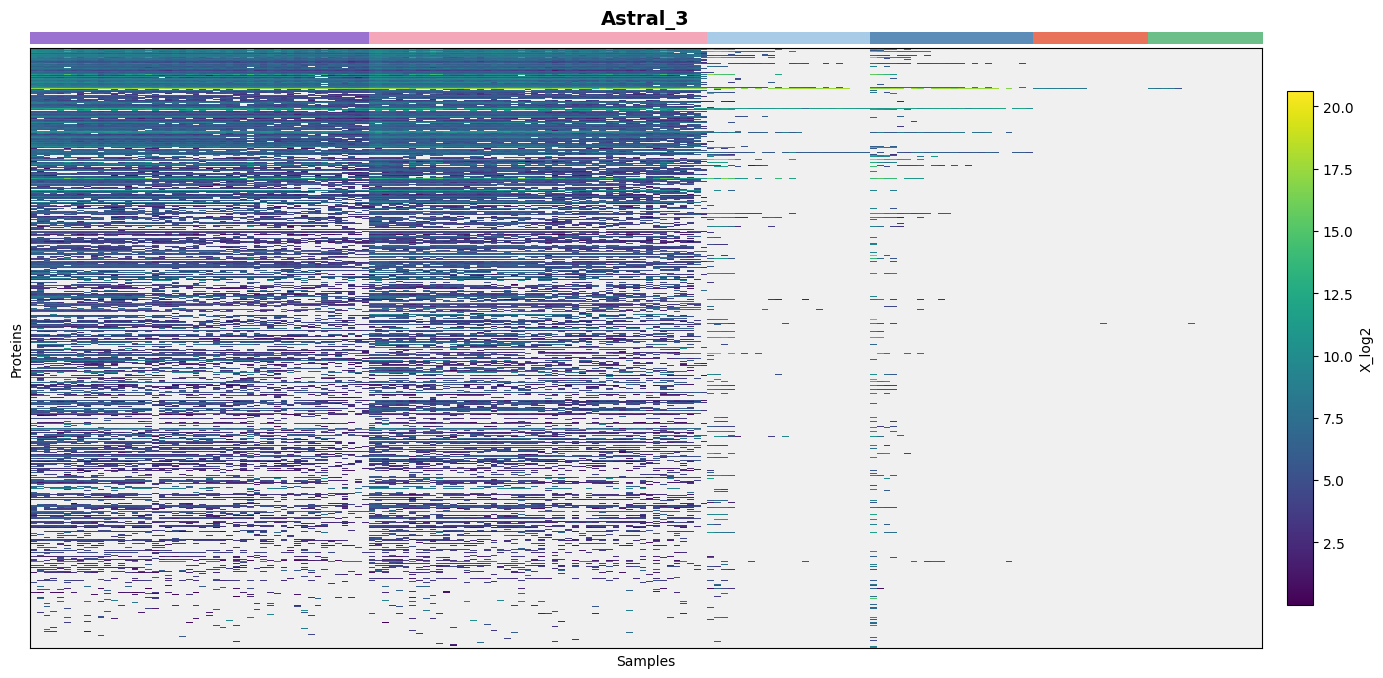

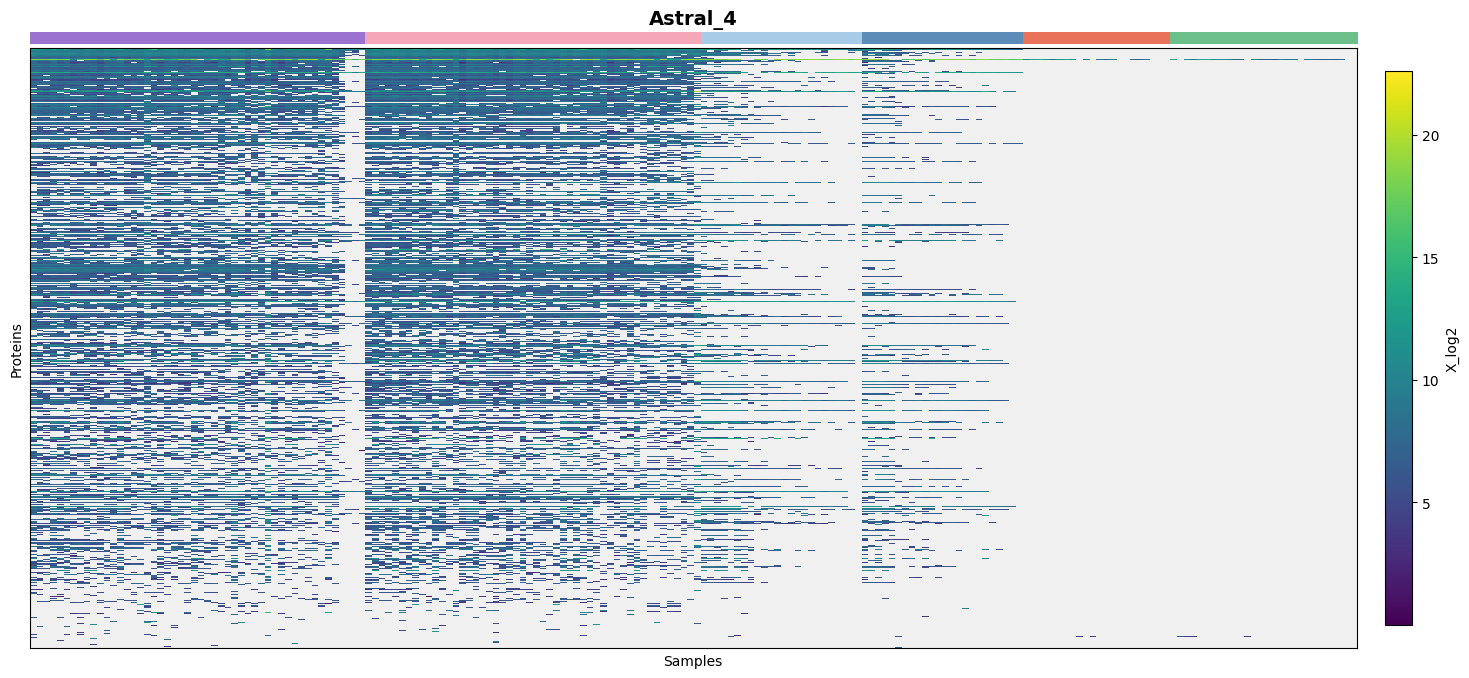

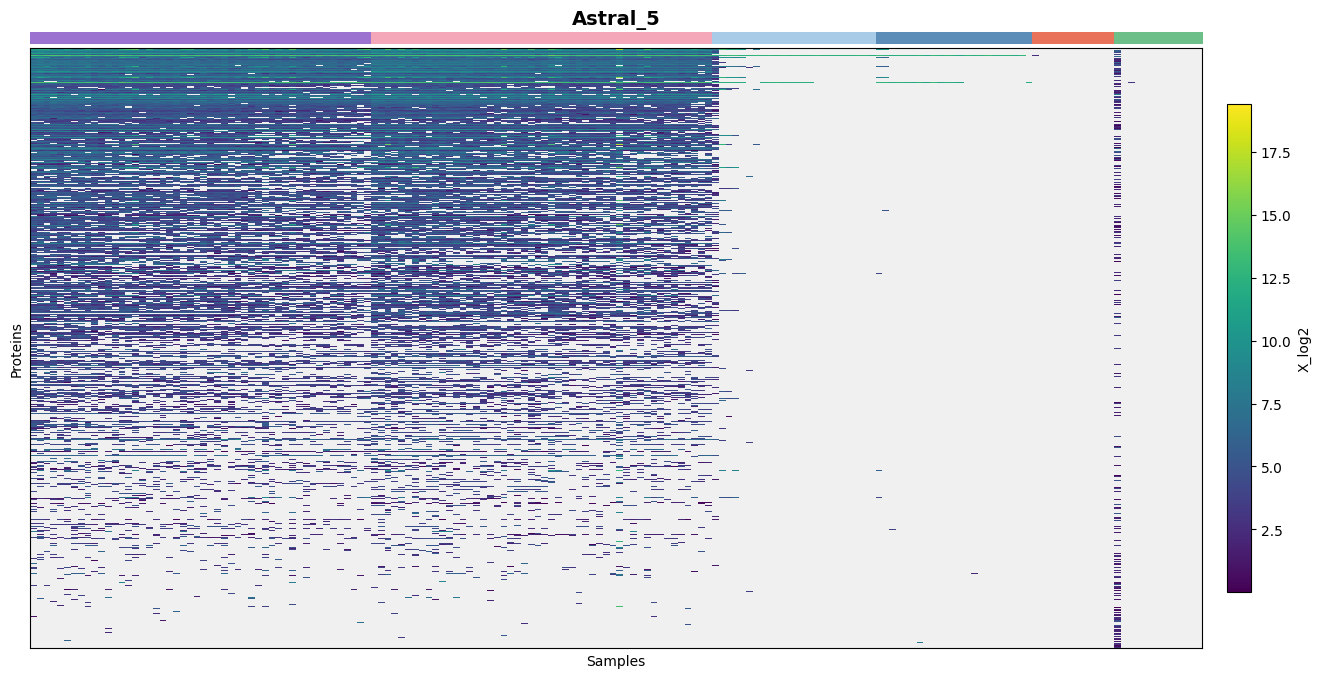

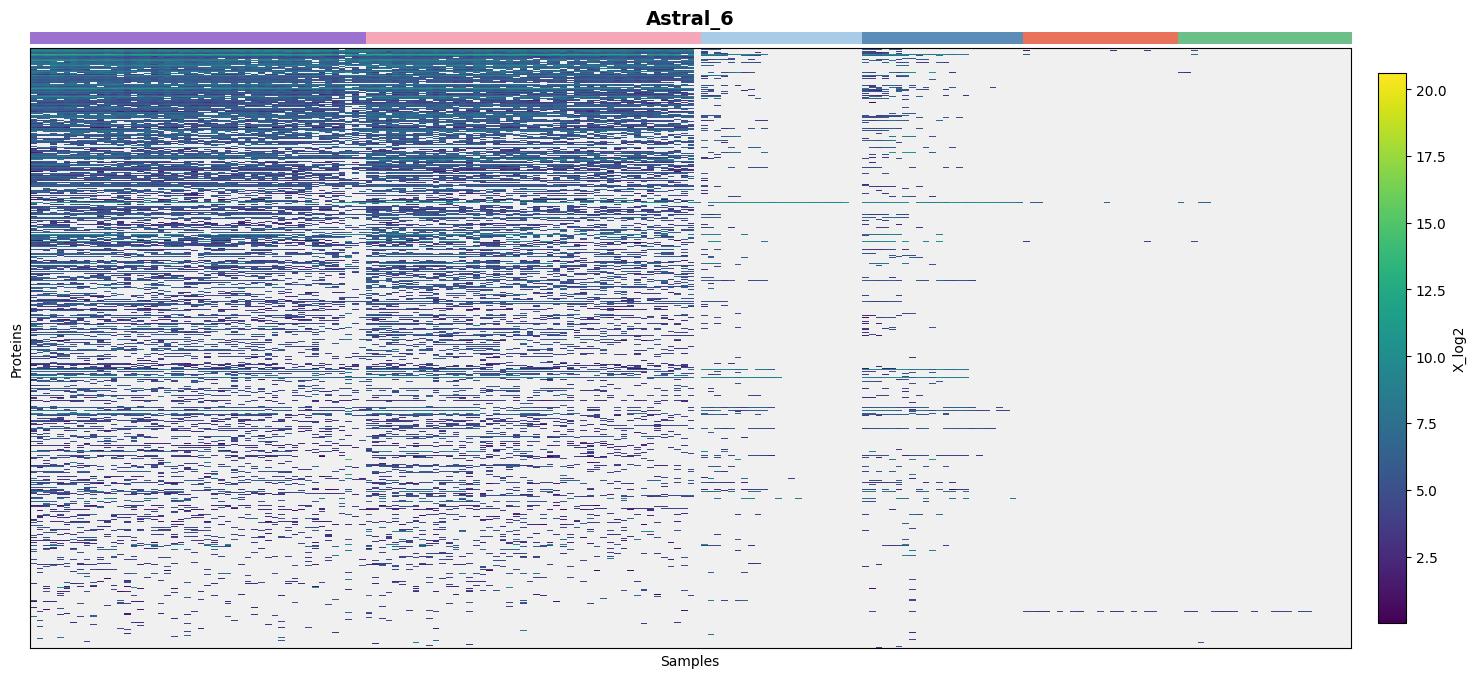

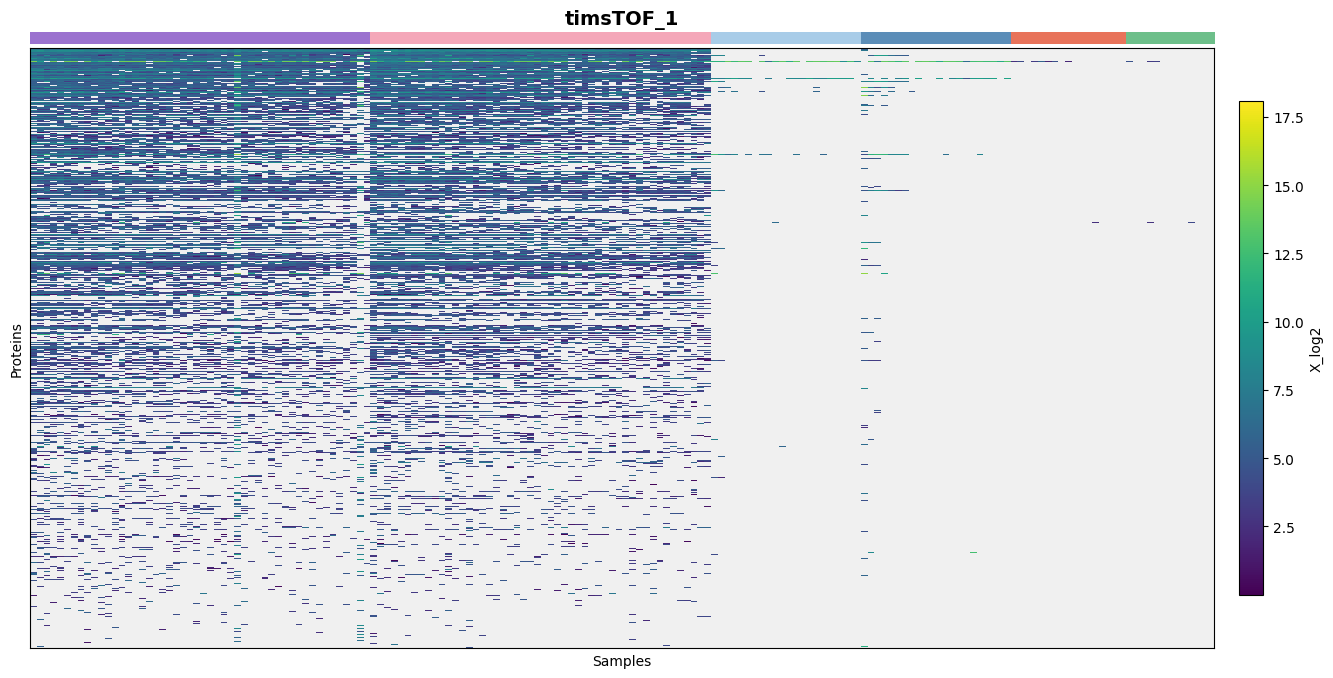

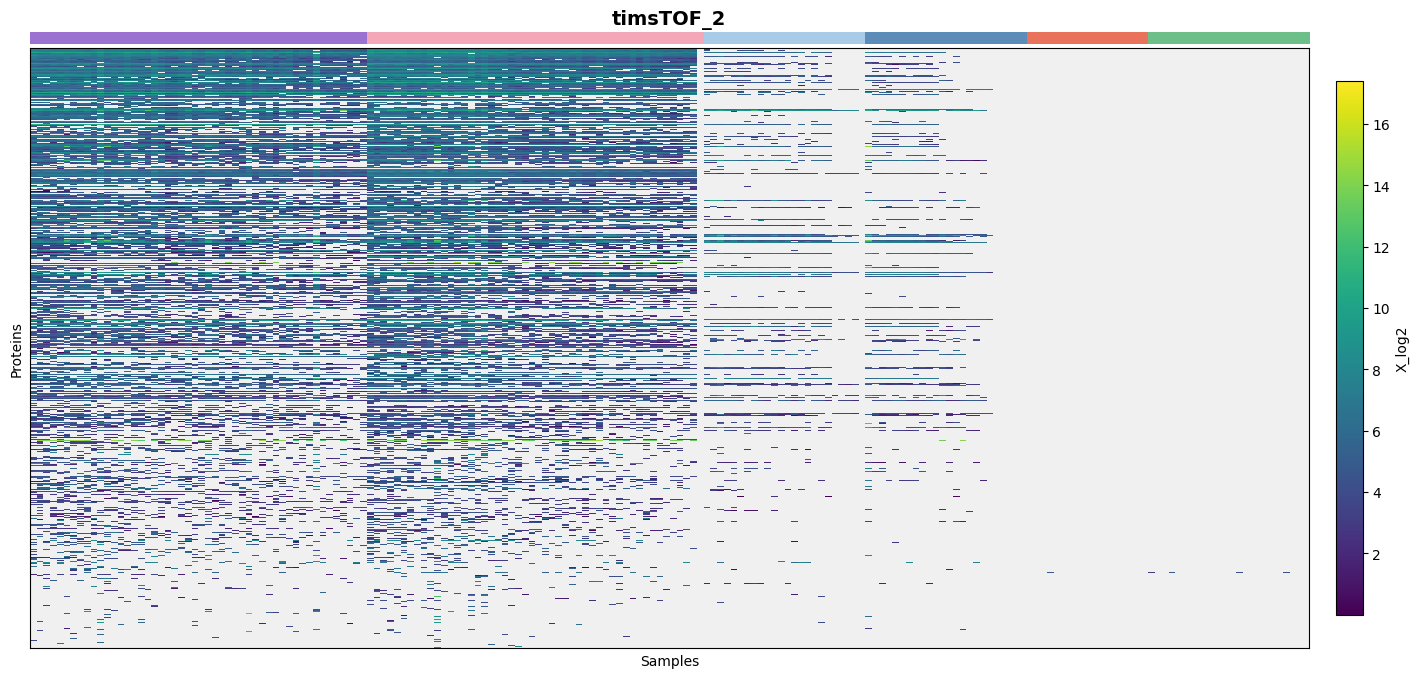

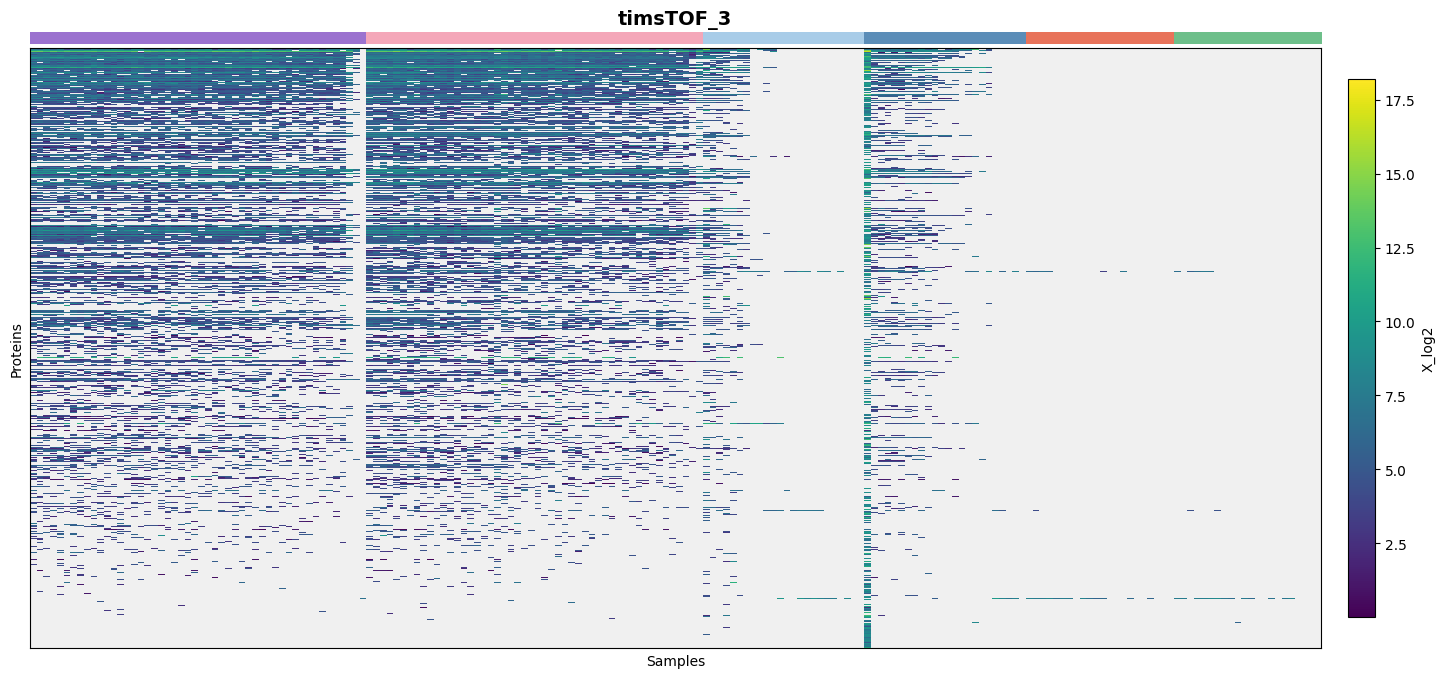

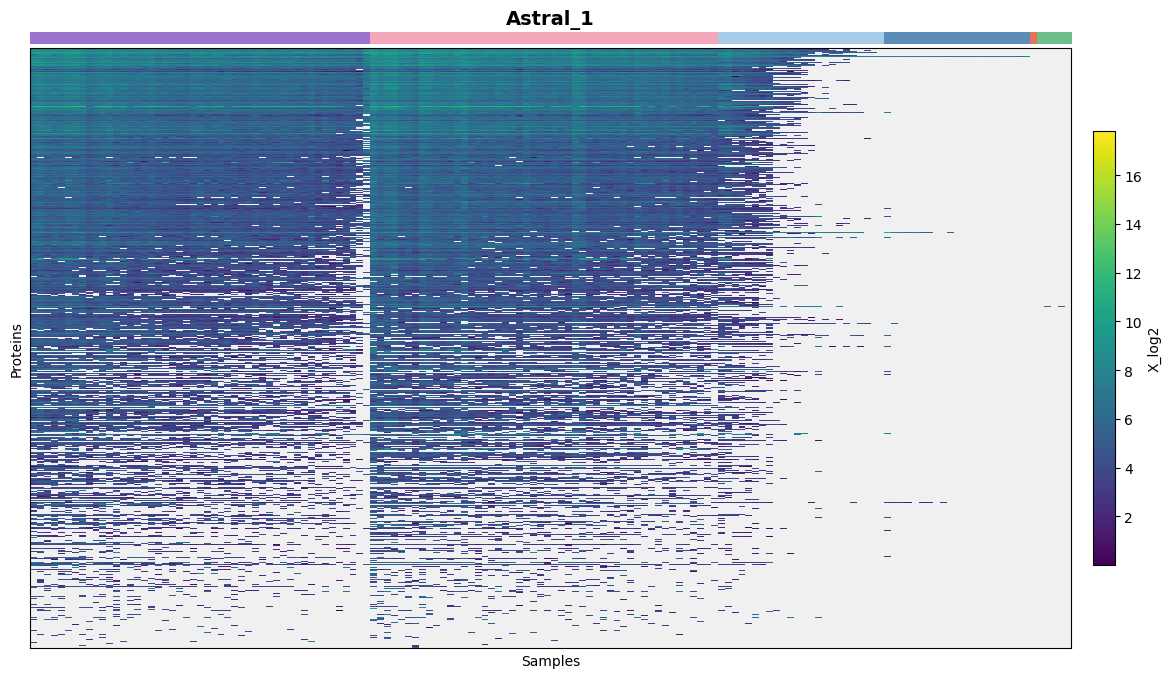

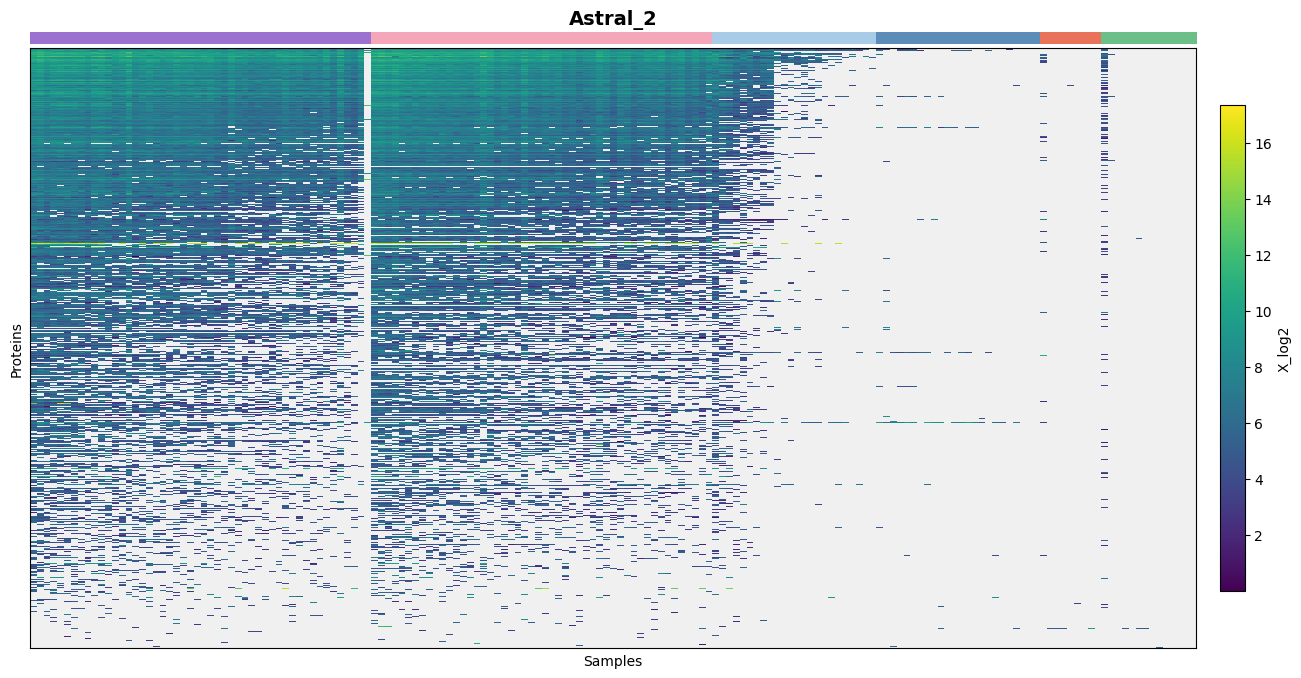

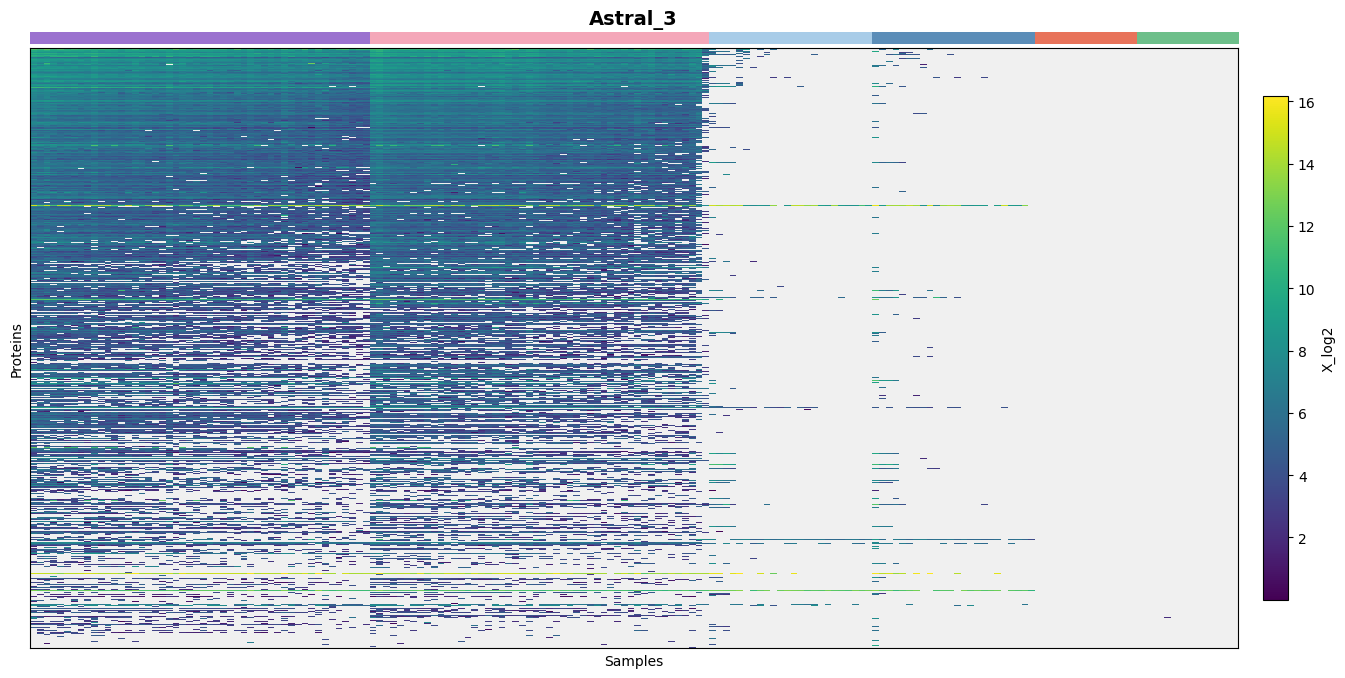

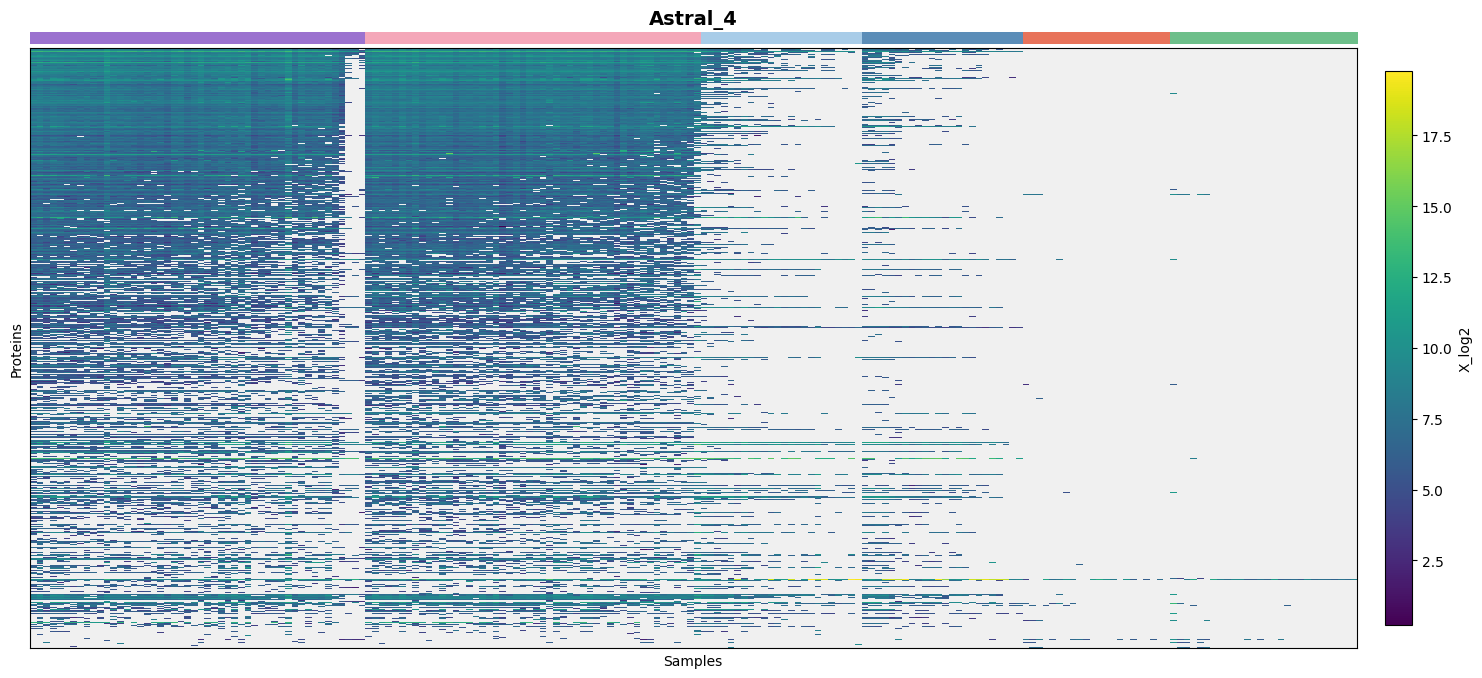

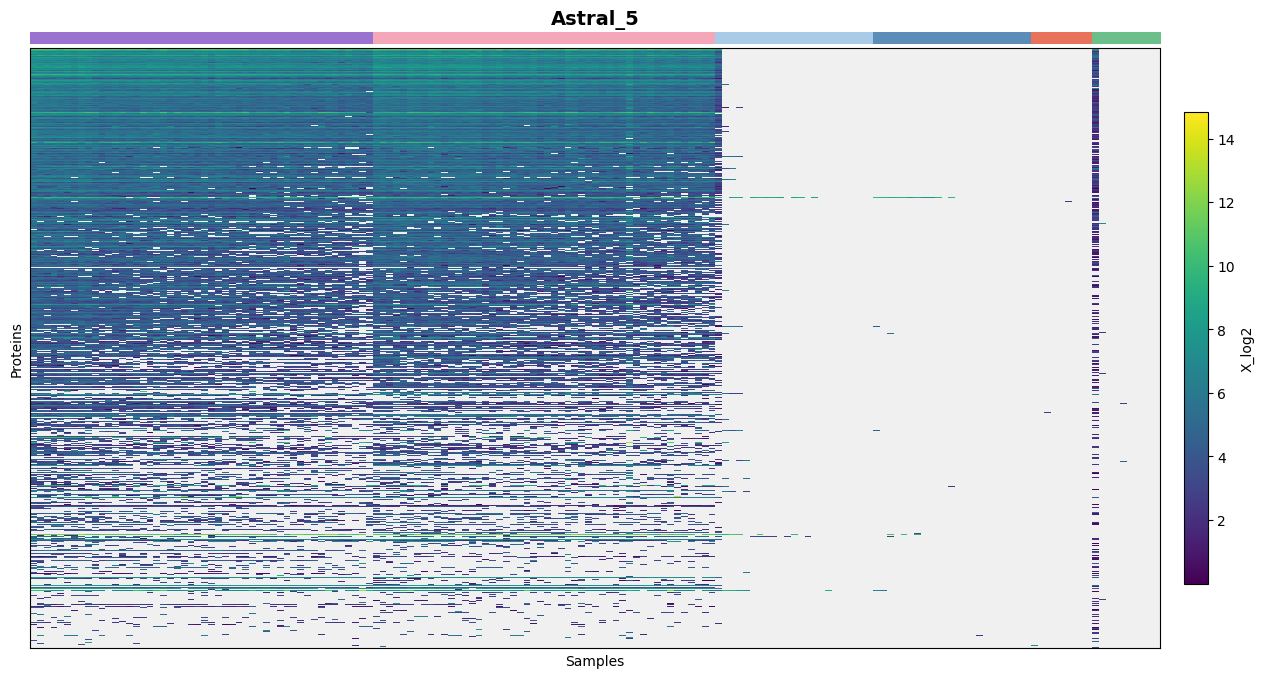

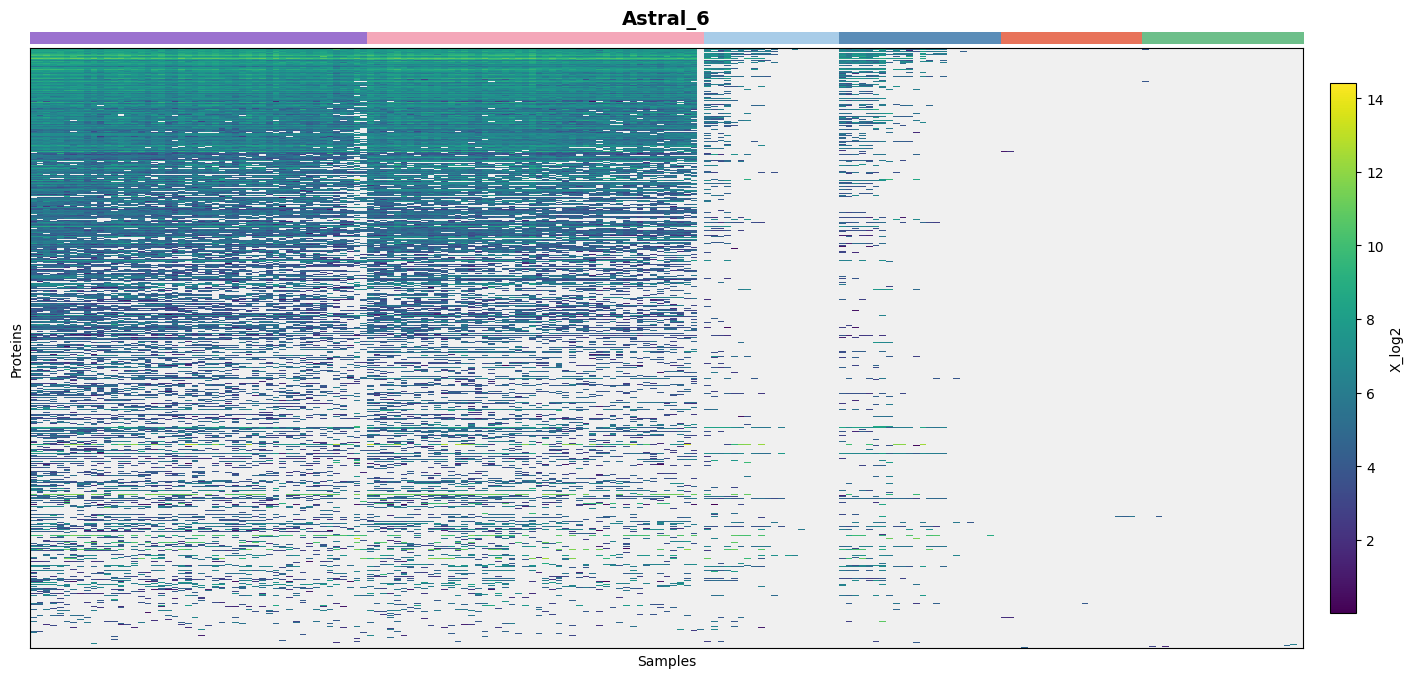

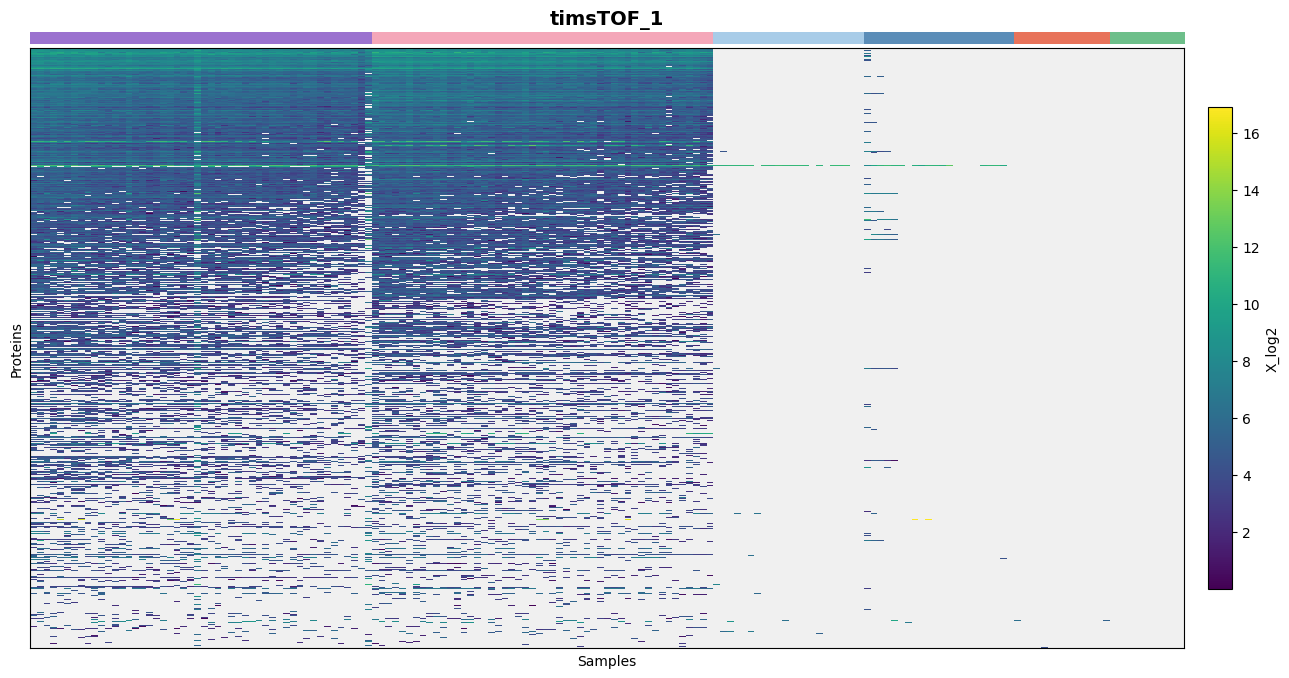

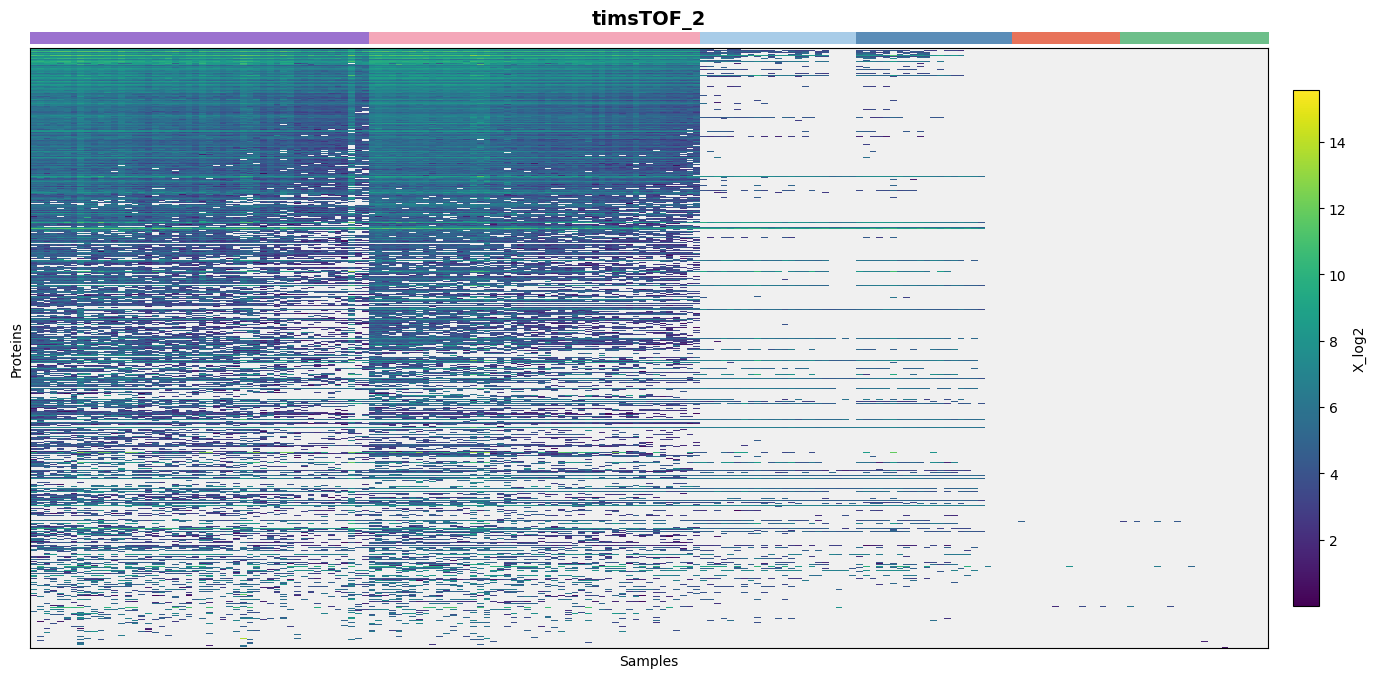

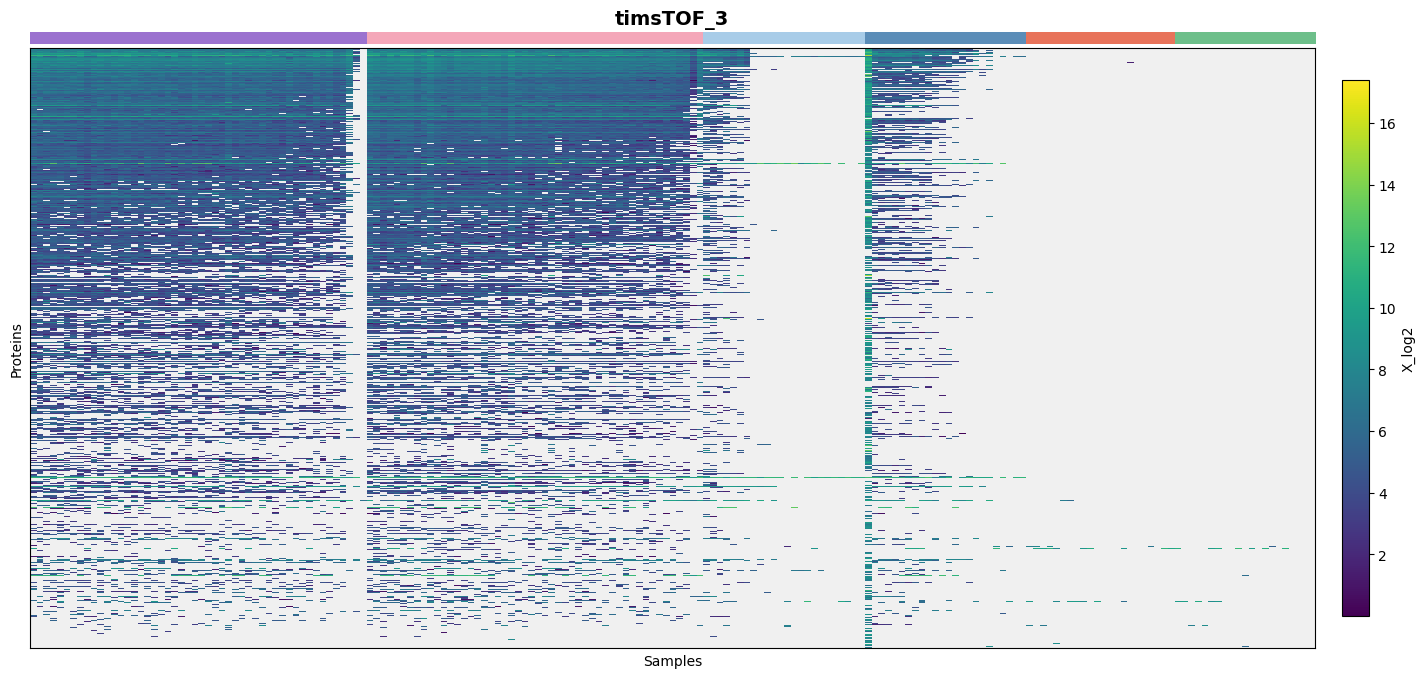

In [15]:
binary_dfs = plot_identification_heatmap(
    adata_precursor,
    conditions                = ['K562', 'HEK293T', 'Sorting control', 'Processing control', 'Cellenone blank', 'Site specific blanks'],
    global_protein_order      = True,
    sort_conditions           = ['K562', 'HEK293T'],
    max_samples_per_condition = 50,
    conditions_to_sample      = ['K562', 'HEK293T'],
    save_dir                  = os.path.join(FIGURES_OUT, 'Figure_3', 'ID_Heatmap'),
    show                      = SHOW_FIGURES,
    layer                     = 'X_log2'
)

binary_dfs = plot_identification_heatmap(
    adata_protein[:, ~adata_protein.var['Contaminant']],
    conditions                = ['K562', 'HEK293T', 'Sorting control', 'Processing control', 'Cellenone blank', 'Site specific blanks'],
    global_protein_order      = True,
    sort_conditions           = ['K562', 'HEK293T'],
    max_samples_per_condition = 50,
    conditions_to_sample      = ['K562', 'HEK293T'],
    save_dir                  = os.path.join(FIGURES_OUT, 'Figure_3', 'ID_Heatmap'),
    show                      = SHOW_FIGURES,
    layer                     = 'X_log2'
)

## 5. Save

Write both AnnData objects back to `Data/AnnData/`. The objects now carry updated identification counts (`n_precursors`, `n_proteins`, `n_precursors_withCont`, `n_proteins_withCont`, `pct_contaminant`) in `obs` and pre-computed CV matrices in `uns['CVs']`.

In [17]:
# DIANN
# ANNDATA_OUT = os.path.join(
#     ROOT_OUT,
#     'AnnData',
#     'DIANN',
#     'v2.6',
#     'second_pass',
#     'out'
# )
# Spectronaut
ANNDATA_OUT = os.path.join(
    ROOT_OUT,
    'AnnData',
    'Spectronaut',
    'out'
)

Path(ANNDATA_OUT).mkdir(parents=True, exist_ok=True)

adata_precursor.write_h5ad(
    os.path.join(ANNDATA_OUT, 'adata_precursor.h5ad'),
    convert_strings_to_categoricals=False
)
adata_protein.write_h5ad(
    os.path.join(ANNDATA_OUT, 'adata_protein.h5ad'),
    convert_strings_to_categoricals=False
)

In [18]:
ANNDATA_OUT = '/public/conode53/sam/SCI_paper/Zenodo/Data/AnnData/Spectronaut'

Path(ANNDATA_OUT).mkdir(parents=True, exist_ok=True)

adata_precursor.write_h5ad(
    os.path.join(ANNDATA_OUT, 'adata_precursor.h5ad'),
    convert_strings_to_categoricals=False
)
adata_protein.write_h5ad(
    os.path.join(ANNDATA_OUT, 'adata_protein.h5ad'),
    convert_strings_to_categoricals=False
)

You can check the size of the anndata object and its components anytime by using `inspect_anndata_size`.

In [19]:
from SCI_py.data.utilities import inspect_anndata_size

inspect_anndata_size(adata_precursor, 'adata_precursor')
inspect_anndata_size(adata_protein, 'adata_protein')

adata_precursor: 3114 obs × 72061 vars
Total estimated size: 11100.9 MB

adata_protein: 3114 obs × 7231 vars
Total estimated size: 780.5 MB



,component,detail,size_mb
0,X,ndarray,180.14
1,layers,PG.Cscore,180.14
2,layers,PG.Qvalue,180.14
3,layers,X_log2,180.14
4,uns,CVs,30.38
5,var,7231 × 19,17.62
6,obs,3114 × 30,11.93
